# สร้างแบบจำลอง — การดัดแปลงผิว HTL ส่งผลต่อผลลัพธ์เท่าไร ผ่านกลไกอะไร

โน้ตบุ๊กนี้ทำตามแผนที่ประกาศไว้ใน `reports/report.html` §4.4 และ `DATA_PREPARATION.md` ข้อ 5
โดยรับชุดตัวแปรที่ผ่านการคัดกรองมาแล้วจาก `eda_htl_modification.ipynb`

| หัวข้อในแผน | ทำที่ไหนในโน้ตบุ๊กนี้ |
|---|---|
| Random Forest + SHAP | §3–§5 |
| ตัดทั้งเปเปอร์ออกทีละฉบับ (`LeaveOneGroupOut`) | §2 |
| ฝึกทำนาย Voc · Jsc · FF แยกกัน แล้วคูณกลับเป็น PCE | §3.2 · §4.2 |
| รวมคำทำนายจากทุกรอบมาประเมินทีเดียว ไม่ใช่เฉลี่ยคะแนนรายรอบ | §2 |
| ตัวควบคุมบังคับ `a_Cs` `a_FA` `x_Br` `etl_family` | §1.2 |
| ช่วงความเชื่อมั่นของผลต่างระดับเปเปอร์ (bootstrap) | §6 · §7 |
| การวิเคราะห์กลไกผ่าน VTFL | §7 |
| ประกาศอคติจากการตีพิมพ์ | §10 |

---

## กติกา 4 ข้อที่บังคับทุกอย่างในโน้ตบุ๊กนี้

**1 · กลุ่มของการแบ่งข้อมูลคือเปเปอร์ ไม่ใช่อุปกรณ์**
อุปกรณ์จากเปเปอร์เดียวกันใช้สูตรการผลิตชุดเดียวกัน ถ้าแบ่งแบบสุ่มจะมีอุปกรณ์พี่น้องอยู่ทั้งสองฝั่ง
คะแนนที่ได้จะเป็นการจำสูตรของเปเปอร์ ไม่ใช่การเรียนกลไก

**2 · รวมคำทำนายจากทุกรอบมาประเมินทีเดียว**
แต่ละรอบเหลืออุปกรณ์ทดสอบเพียง 2–5 ตัว (13 รอบมีไม่เกิน 2 ตัว) — คะแนน $R^2$ ของรอบที่มี 2 ตัว
ไม่มีความหมายทางสถิติ และการเฉลี่ยคะแนนพวกนั้นยิ่งทำให้ตัวเลขผันผวนโดยไม่เพิ่มข้อมูล
จึงเก็บคำทำนายนอกกลุ่มฝึก (out-of-fold) ของทุกอุปกรณ์ไว้ แล้วคิดคะแนนครั้งเดียวบนกองรวม

**3 · ค่าที่หายห้ามเติมข้ามเปเปอร์**
ข้อมูลหายเป็นก้อนตามเปเปอร์ (เปเปอร์ที่ไม่วัด SCLC ก็ไม่มีทั้งฉบับ) การเติมค่าข้ามเปเปอร์
เท่ากับประดิษฐ์ข้อมูลของแล็บหนึ่งจากอีกแล็บหนึ่ง — Random Forest รองรับค่าว่างได้เองจึงไม่ต้องเติม

**4 · ไม่จูนไฮเปอร์พารามิเตอร์**
ข้อมูลไม่พอทำ nested CV ที่เชื่อถือได้ ค่าที่ใช้จึงตั้งจากขนาดข้อมูลตรง ๆ แล้วประกาศไว้
ตัวเลขที่รายงานจึงไม่ได้ถูกคัดมาให้สวย

In [1]:
from math import comb
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 0

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"
AUD = ROOT / "processed" / "audit"
OUT = ROOT / "processed" / "model"
OUT.mkdir(parents=True, exist_ok=True)

tt = pd.read_csv(V2 / "target_table.csv")
layers = pd.read_csv(V2 / "layers.csv")
mats = pd.read_csv(V2 / "materials.csv")
tt["paper"] = tt["device_id"].str.rsplit("_Sample", n=1).str[0]

_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})


def spearman(x, y):
    """rho, n -- เขียนเองให้ผลตรงกับโน้ตบุ๊กอื่นในโปรเจกต์"""
    m = pd.notna(x) & pd.notna(y)
    if m.sum() < 3:
        return np.nan, int(m.sum())
    xr, yr = pd.Series(x)[m].rank(), pd.Series(y)[m].rank()
    if xr.nunique() < 2 or yr.nunique() < 2:
        return np.nan, int(m.sum())
    return float(np.corrcoef(xr, yr)[0, 1]), int(m.sum())


def sign_test(vals):
    """p สองด้านแบบ exact binomial -> (p, k_pos, n) · ทิ้งค่า 0 และ NaN"""
    v = [x for x in vals if pd.notna(x) and x != 0]
    n, k = len(v), sum(1 for x in v if x > 0)
    if n == 0:
        return np.nan, 0, 0
    pmf = [comb(n, i) * 0.5 ** n for i in range(n + 1)]
    return min(1.0, sum(q for q in pmf if q <= pmf[k] + 1e-12)), k, n


def boot_ci(vals, stat=np.median, B=4000, seed=SEED):
    """ช่วงความเชื่อมั่น 95% แบบ percentile bootstrap -- หน่วยที่สุ่มซ้ำคือ 'เปเปอร์' เสมอ"""
    v = np.asarray([x for x in vals if pd.notna(x)], dtype=float)
    if len(v) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    draws = [stat(rng.choice(v, size=len(v), replace=True)) for _ in range(B)]
    return float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))


def short(s, n=26):
    s = str(s)
    return s if len(s) <= n else s[:n - 1] + "…"


print(f"อุปกรณ์ {len(tt)} · เปเปอร์ {tt.paper.nunique()} · shap {shap.__version__} · ฟอนต์กราฟ {FONT}")

อุปกรณ์ 95 · เปเปอร์ 31 · shap 0.52.0 · ฟอนต์กราฟ Leelawadee UI


C:\Users\acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. เมทริกซ์ออกแบบ

### 1.1 สร้างตัวแปรชุดเดียวกับที่ EDA คัดไว้ แล้วพิสูจน์ว่าตรงกันจริง

ตัวแปรฝั่ง HTL ไม่ได้อยู่ใน `target_table` ทั้งหมด — ต้องประกอบขึ้นจาก `layers` / `materials`
ด้วยกติกาชุดเดียวกับ `eda_htl_modification.ipynb` ถ้าสองโน้ตบุ๊กสร้างไม่เหมือนกัน ข้อสรุปจะไม่ต่อกัน

เซลล์ถัดไปจึง **ตรวจย้อนกับ `processed/audit/eda_feature_screen.csv` ที่ EDA เขียนไว้**
ถ้าจำนวนอุปกรณ์ที่มีค่า หรือจำนวนเปเปอร์ที่ตัวแปรแปรค่า ไม่ตรงแม้แต่ตัวเดียว เซลล์จะหยุดทันที

In [2]:
F = tt.set_index("device_id").copy()

# ---- ชั้น 2 (HTL): วัสดุบอกทั้งการเจือสารและวิธีผลิต ----
F["htl_material"] = layers[layers.layer_id == 2].groupby("device_id")["material"].first()


def htl_dope(m):
    """สารที่เจือลงในเนื้อ NiOx -- อ่านจากรูปแบบ 'X:NiO...' หรือชื่อสารประกอบที่รู้จัก"""
    if not isinstance(m, str):
        return np.nan
    hit = re.match(r"\s*([A-Z][a-z]?)\s*:\s*NiO", m)
    if hit:
        return hit.group(1)
    if "TTTS" in m:
        return "TTTS"
    return "ไม่เจือ"


def htl_route(m):
    """วิธีขึ้นฟิล์ม HTL -- คนละกลไกกันจริง ๆ ระหว่างสารละลาย/อนุภาค กับการสปัตเตอร์"""
    if not isinstance(m, str):
        return np.nan
    s = m.lower()
    if "sputter" in s:
        return "สปัตเตอร์"
    if "ebe" in s or "e-beam" in s:
        return "ลำอิเล็กตรอน"
    if "np" in s or "nanoparticle" in s:
        return "อนุภาคนาโน"
    return "สารละลาย"


F["htl_dope"] = F["htl_material"].map(htl_dope)
F["htl_route"] = F["htl_material"].map(htl_route)

# ---- ชั้น 3 (เคลือบผิว HTL): สาร + ตระกูล + ปริมาณ ----
F["htl_mod_material"] = (layers[layers.layer_id == 3].groupby("device_id")["material"]
                         .apply(lambda s: " + ".join(sorted(s.dropna().unique()))).replace("", np.nan))
F["htl_mod"] = F["htl_mod_kind"].notna()


def mod_class(mat):
    if not isinstance(mat, str) or not mat:
        return "ไม่ดัดแปลง"
    m = mat.upper()
    if any(k in m for k in ("PACZ", "PADBC", "PADMAC", "SAM")):
        return "SAM (คาร์บาโซล)"
    # BMIM* คือของเหลวไอออนิกอิมิดาโซเลียม · TEACL เกลือแอมโมเนียมควอเทอร์นารี · LIF เกลืออนินทรีย์
    #   เดิมรายการคีย์เวิร์ดมีแค่ PF6/CSI/EMIMI/KI/NAI ทำให้ BMIMBF4/BMIMBr/BMIMGly หลุดไปกลุ่มอินทรีย์
    #   ขณะที่ BMIMPF6 จากเปเปอร์เดียวกันเข้ากลุ่มเกลือ -- การทดลองชุดเดียวถูกฉีกเป็นสองกลุ่ม
    if any(k in m for k in ("PF6", "CSI", "EMIMI", "BMIM", "KI", "NAI", "TEACL", "LIF", "RBCL")):
        return "เกลือไอออน"
    if any(k in m for k in ("AL2O3", "TIO2", "SIO2", "MGO")):
        return "ออกไซด์"
    return "โมเลกุลอินทรีย์"


F["htl_mod_class"] = F["htl_mod_material"].map(mod_class)

_m3 = mats[mats.layer_id == 3].copy()
_m3["amt"] = pd.to_numeric(_m3.get("amount_parsed", _m3.get("amount")), errors="coerce")
F["htl_dose"] = _m3.dropna(subset=["amt"]).groupby("device_id")["amt"].max()

_th = layers.copy()
_th["thk"] = pd.to_numeric(_th.get("thickness_nm_parsed", _th.get("thickness_nm")), errors="coerce")
F["htl_thick"] = _th[_th.layer_id == 2].groupby("device_id")["thk"].first()

# htl_mod_kind: ค่าว่างแปลว่า "ไม่ดัดแปลง" ซึ่งเป็นระดับจริง ไม่ใช่ข้อมูลหาย
F["htl_mod_kind"] = F["htl_mod_kind"].fillna("ไม่ดัดแปลง")
F = F.reset_index()

TARGET = ["voc", "jsc", "ff", "pce"]
MEDIATOR = ["vtfl", "trap_density", "contact_angle", "grain_size",
            "afm_rms", "vbm", "work_function", "hi"]
STABILITY = ["retention_25c", "degradation_rate"]

# ---- ด่านตรวจ: ต้องตรงกับที่ EDA เขียนไว้ทุกตัว ----
_ref = pd.read_csv(AUD / "eda_feature_screen.csv").set_index("ตัวแปร")
_bad = []
for c in ["htl_mod", "htl_mod_class", "htl_dope", "htl_route", "htl_dose", "htl_thick",
          "coat_htl", "n_coating_layers", "a_Cs", "a_FA", "x_Br", "etl_family"]:
    if c not in _ref.index:
        continue
    n = len(F) if c == "htl_mod_kind" else int(F[c].notna().sum())
    w = int((F.groupby("paper")[c].nunique(dropna=True) > 1).sum())
    if (n, w) != (int(_ref.loc[c, "n"]), int(_ref.loc[c, "เปเปอร์ที่แปร"])):
        _bad.append(f"{c}: ที่นี่ (n={n}, แปร {w} เปเปอร์) · EDA (n={_ref.loc[c,'n']}, แปร {_ref.loc[c,'เปเปอร์ที่แปร']} เปเปอร์)")
assert not _bad, "ตัวแปรไม่ตรงกับ EDA:\n  " + "\n  ".join(_bad)
print(f"ตรวจแล้ว: ตัวแปร {len(_ref)} ตัวสร้างได้ตรงกับ eda_feature_screen.csv ทุกตัว")

display(F[["device_id", "paper", "htl_material", "htl_mod_kind", "htl_mod_class",
           "htl_dope", "htl_route", "htl_dose", "pce", "vtfl"]].head(6))

ตรวจแล้ว: ตัวแปร 24 ตัวสร้างได้ตรงกับ eda_feature_screen.csv ทุกตัว


,device_id,paper,htl_material,htl_mod_kind,htl_mod_class,htl_dope,htl_route,htl_dose,pce,vtfl
0,10.1002admi.202500231_Sample1,10.1002admi.202500231,NiOx NPs,ไม่ดัดแปลง,ไม่ดัดแปลง,ไม่เจือ,อนุภาคนาโน,NaN,16.31,NaN
1,10.1002admi.202500231_Sample2,10.1002admi.202500231,NiOx NPs,additive,เกลือไอออน,ไม่เจือ,อนุภาคนาโน,25.0,17.11,NaN
2,10.1002admi.202500231_Sample3,10.1002admi.202500231,NiOx NPs,additive,เกลือไอออน,ไม่เจือ,อนุภาคนาโน,25.0,16.97,NaN
3,10.1002admi.202500231_Sample4,10.1002admi.202500231,NiOx NPs,additive,เกลือไอออน,ไม่เจือ,อนุภาคนาโน,25.0,16.25,NaN
4,10.1007_s10854-017-8094-9_Sample1,10.1007_s10854-017-8094-9,NiOx NPs,ไม่ดัดแปลง,ไม่ดัดแปลง,ไม่เจือ,อนุภาคนาโน,NaN,12.70,NaN
5,10.1007_s10854-017-8094-9_Sample2,10.1007_s10854-017-8094-9,NiOx NPs,ไม่ดัดแปลง,ไม่ดัดแปลง,ไม่เจือ,อนุภาคนาโน,NaN,12.80,NaN


### 1.2 เลือกตัวแปรเข้าโมเดล — และตัดตัวที่บอกเรื่องเดียวกัน

EDA §4 เตือนว่าถ้าใส่ตัวแปรที่ซ้ำซ้อนกันพร้อมกัน น้ำหนักจะถูกแบ่งกันจนอ่านไม่ออก
`coat_htl` และ `n_coating_layers` เกือบเป็นฟังก์ชันของ `htl_mod_kind` — และ `htl_mod_kind`
ให้ข้อมูล**มากกว่า** เพราะแยก *เคลือบทับผิว* ออกจาก *ผสมลงในน้ำหมึก* ซึ่งคนละกลไกกัน

| บทบาท | ตัวแปร | เหตุผล |
|---|---|---|
| **ตัวแปรหลัก** | `htl_mod_kind` (ไม่ดัดแปลง · coating · additive) | สิ่งที่คำถามวิจัยถามตรง ๆ · แปรค่าใน 22/31 เปเปอร์ |
| | `htl_dope` (สารเจือในเนื้อ NiOx) | คนละกลไกกับการเคลือบผิว · แปรค่าใน 4 เปเปอร์ |
| | `htl_route` (วิธีขึ้นฟิล์ม HTL) | process knob ตัวเดียวที่แปรภายในเปเปอร์ได้จริง · 6 เปเปอร์ |
| **ตัวควบคุมบังคับ** | `a_Cs` `a_FA` `x_Br` | สูตรเคมีกระทบ Voc/Jsc ทางฟิสิกส์โดยตรง — confounder ตัวใหญ่สุด |
| | `etl_family` | ชนิดวัสดุชั้น ETL กระทบการดึงพาหะ |
| **ตัดออก** | `coat_htl` · `n_coating_layers` | ซ้ำกับ `htl_mod_kind` (ดูตารางไขว้ด้านล่าง) |
| | `htl_mod_class` | ซ้ำกับ `htl_mod_kind` ในแกน "ดัดแปลง/ไม่ดัดแปลง" → **แยกไปเป็นโมเดลของ §6 ต่างหาก** |
| | `htl_dose` | มีค่าแค่ 49/95 → ถ้าใส่รวมจะตัดอุปกรณ์ทิ้งครึ่งหนึ่ง → **แยกไปเป็น §8** |

> ⚠️ ตัวควบคุมทั้งสี่ตัว **แปรค่าภายในเปเปอร์ 0–1 ฉบับ** ใส่ไว้เพื่อกันไม่ให้โมเดลโยนความดีความชอบ
> ของสูตรเคมีไปให้การดัดแปลง HTL เท่านั้น — **ห้ามอ่านค่า SHAP ของมันเป็นกลไก** (รายงาน §3.1)

In [3]:
MAIN = ["htl_mod_kind", "htl_dope", "htl_route"]
CTRL = ["a_Cs", "a_FA", "x_Br", "etl_family"]

print("หลักฐานว่า coat_htl / n_coating_layers ซ้ำกับ htl_mod_kind:")
for c in ["coat_htl", "n_coating_layers"]:
    ct = pd.crosstab(F[c], F["htl_mod_kind"])
    acc = ct.max(axis=1).sum() / ct.values.sum()
    print(f"\n  {c} -- ทาย htl_mod_kind จากตัวนี้ถูก {acc:.0%} ของอุปกรณ์")
    display(ct)


def design(cols, frame):
    """one-hot ตัวจัดกลุ่ม · ตัวเลขปล่อยตามเดิม -> (X, คอลัมน์ -> ตัวแปรต้นสังกัด)"""
    parts, owner = [], {}
    for c in cols:
        s = frame[c]
        if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s) and s.nunique(dropna=True) > 2:
            parts.append(s.astype(float).rename(c))
            owner[c] = c
        else:
            d = pd.get_dummies(s.astype("object").where(s.notna(), "—"), prefix=c).astype(float)
            for k in d.columns:
                owner[k] = c
            parts.append(d)
    return pd.concat(parts, axis=1), owner


X, OWNER = design(MAIN + CTRL, F)
G = F["paper"].values
print(f"\nเมทริกซ์ออกแบบ: {X.shape[0]} อุปกรณ์ x {X.shape[1]} คอลัมน์ (จาก {len(MAIN+CTRL)} ตัวแปร) · {F.paper.nunique()} กลุ่ม")
print("คอลัมน์:", list(X.columns))

หลักฐานว่า coat_htl / n_coating_layers ซ้ำกับ htl_mod_kind:

  coat_htl -- ทาย htl_mod_kind จากตัวนี้ถูก 97% ของอุปกรณ์


htl_mod_kind,additive,coating,ไม่ดัดแปลง
coat_htl,,,
False,3,0,39
True,0,53,0



  n_coating_layers -- ทาย htl_mod_kind จากตัวนี้ถูก 84% ของอุปกรณ์


htl_mod_kind,additive,coating,ไม่ดัดแปลง
n_coating_layers,,,
0,0,0,4
1,3,0,23
2,0,27,12
3,0,26,0



เมทริกซ์ออกแบบ: 95 อุปกรณ์ x 19 คอลัมน์ (จาก 7 ตัวแปร) · 31 กลุ่ม
คอลัมน์: ['htl_mod_kind_additive', 'htl_mod_kind_coating', 'htl_mod_kind_ไม่ดัดแปลง', 'htl_dope_Cu', 'htl_dope_La', 'htl_dope_Sm', 'htl_dope_TTTS', 'htl_dope_ไม่เจือ', 'htl_route_ลำอิเล็กตรอน', 'htl_route_สปัตเตอร์', 'htl_route_สารละลาย', 'htl_route_อนุภาคนาโน', 'a_Cs', 'a_FA', 'x_Br', 'etl_family_BCP', 'etl_family_C60', 'etl_family_PCBM', 'etl_family_SnO2']


## 2. กติกาการวัดผล — พื้นและเพดานก่อนจะดูคะแนนโมเดล

คะแนน $R^2$ ลอย ๆ ไม่มีความหมายถ้าไม่รู้ว่าอะไรคือ "ทายมั่ว" และอะไรคือ "ดีที่สุดที่เป็นไปได้"
จึงวัดสองเส้นนี้ก่อนด้วยกติกาเดียวกับโมเดล (LOPO + รวมคำทำนายทุกรอบมาคิดทีเดียว)

| เส้น | ทายด้วยอะไร | ความหมาย |
|---|---|---|
| **พื้น** | ค่ากลางของอุปกรณ์ในกลุ่มฝึก | ไม่ใช้ข้อมูลตัวแปรเลย · $R^2 \approx 0$ ตามนิยาม |
| **เพดาน** | ค่ากลางของเปเปอร์ที่ถูกตัดออกเอง | ทายไม่ได้จริงตอนใช้งาน (ต้องรู้คำตอบก่อน) — วัดไว้เพื่อบอกว่า *ตัวตนของเปเปอร์อธิบายความแปรปรวนไปแล้วกี่ %* |

ช่องว่างระหว่างพื้นกับเพดานคือ **ส่วนที่ตัวตนของเปเปอร์กินไป** ส่วนที่เหลือเหนือเพดานเท่านั้น
ที่ตัวแปรของเราจะไปเก็บได้ — ตัวเลขนี้กำหนดว่า §3 จะออกมาหน้าตาแบบไหนตั้งแต่ยังไม่ได้เทรน

In [4]:
LOPO = LeaveOneGroupOut()


def make_rf():
    """ป่าสุ่ม -- ค่าตั้งจากขนาดข้อมูลตรง ๆ ไม่ได้จูน (กติกาข้อ 4)
    min_samples_leaf=2 กันใบที่มีอุปกรณ์เดียว · max_features=0.6 ให้ต้นไม้ต่างกันพอที่ N เล็ก"""
    return RandomForestRegressor(n_estimators=400, min_samples_leaf=2, max_features=0.6,
                                 random_state=SEED, n_jobs=1)


def make_ridge():
    """เชิงเส้นมีการหดค่า -- alpha เลือกด้วย CV ภายในกลุ่มฝึกเท่านั้น ไม่แตะกลุ่มทดสอบ"""
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 24)))


def paper_center(y, papers, index):
    """ลบค่ากลางของเปเปอร์ตัวเอง -- ทำแยกในแต่ละเปเปอร์ จึงไม่มีข้อมูลรั่วข้ามกลุ่ม"""
    s = pd.Series(y, index=index)
    return s - s.groupby(pd.Series(papers, index=index)).transform("mean")


def oof(target, make_model, Xm=None, center=False, feats=None):
    """เทรน-ทำนายแบบตัดทีละเปเปอร์ แล้วคืนคำทำนายนอกกลุ่มฝึกของทุกอุปกรณ์
    center=True -> ทำนาย 'ส่วนต่างจากค่ากลางของเปเปอร์ตัวเอง' แทนค่าสัมบูรณ์"""
    Xm = X if Xm is None else Xm
    if feats is not None:
        Xm = Xm[feats]
    keep = F[target].notna().values
    Xk, yk, gk = Xm[keep], F.loc[keep, target].values, G[keep]
    idx = F.loc[keep, "device_id"].values
    yc = paper_center(yk, gk, idx).values if center else yk

    rec = []
    for tr, te in LOPO.split(Xk, yc, gk):
        m = make_model().fit(Xk.iloc[tr], yc[tr])
        rec.append(pd.DataFrame({"device_id": idx[te], "paper": gk[te],
                                 "y": yc[te], "pred": m.predict(Xk.iloc[te])}))
    return pd.concat(rec, ignore_index=True)


def score(d, label=""):
    e = d["pred"] - d["y"]
    ss = float(((d["y"] - d["y"].mean()) ** 2).sum())
    # หมายเหตุ: ต้องสร้าง dict ด้วย string key ไม่ใช่ keyword argument --
    # Python ทำ NFKC normalization กับชื่อตัวแปร ทำให้ 'ำ' (U+0E33) ถูกแยกเป็น
    # นิคหิต+สระอา แล้วคีย์จะไม่ตรงกับ string literal 'แบบจำลอง' ตอนเรียกใช้
    return {"แบบจำลอง": label,
            "R2": 1 - float((e ** 2).sum()) / ss if ss > 0 else np.nan,
            "MAE": float(e.abs().mean()), "RMSE": float(np.sqrt((e ** 2).mean())), "n": len(d)}


# ---- พื้นและเพดาน วัดด้วยกติกาเดียวกัน ----
rows = []
for target in TARGET:
    keep = F[target].notna()
    y, g = F.loc[keep, target], F.loc[keep, "paper"]
    floor = pd.DataFrame({"y": y.values, "pred": [y[g != p].mean() for p in g]})   # ค่ากลางของกลุ่มฝึก
    ceil = pd.DataFrame({"y": y.values, "pred": y.groupby(g).transform("mean").values})
    rows.append(dict(ผลลัพธ์=target, **{k: v for k, v in score(floor).items() if k != "แบบจำลอง"},
                     เพดาน_R2=score(ceil)["R2"]))
BASE_TBL = pd.DataFrame(rows).rename(columns={"R2": "พื้น_R2", "MAE": "พื้น_MAE", "RMSE": "พื้น_RMSE"})
display(BASE_TBL.set_index("ผลลัพธ์").round(3))
print("อ่านว่า: 'เพดาน_R2' คือสัดส่วนความแปรปรวนที่อธิบายได้ด้วยการรู้แค่ว่าเปเปอร์ไหนเป็นคนทำ")
print("         ส่วนที่เหลือ (1 - เพดาน) คือเพดานจริงของสิ่งที่ตัวแปรระดับอุปกรณ์จะไปเก็บได้")

,พื้น_R2,พื้น_MAE,พื้น_RMSE,n,เพดาน_R2
ผลลัพธ์,,,,,
voc,-0.059,0.068,0.082,94,0.833
jsc,-0.058,1.705,2.075,94,0.800
ff,-0.076,6.043,7.903,94,0.869
pce,-0.066,3.332,4.161,93,0.833


อ่านว่า: 'เพดาน_R2' คือสัดส่วนความแปรปรวนที่อธิบายได้ด้วยการรู้แค่ว่าเปเปอร์ไหนเป็นคนทำ
         ส่วนที่เหลือ (1 - เพดาน) คือเพดานจริงของสิ่งที่ตัวแปรระดับอุปกรณ์จะไปเก็บได้


## 3. แบบจำลองที่ 1 — ทำนายค่าสัมบูรณ์ของเปเปอร์ที่ไม่เคยเห็น

นี่คือรูปแบบที่งาน ML สายเพอรอฟสไกต์ส่วนใหญ่ทำ: เทรนข้ามแล็บแล้วทำนายค่าจริงของอุปกรณ์ใหม่

**สิ่งที่ต้องระวังคือ $R^2$ ที่ออกมาเป็นบวกไม่ได้แปลว่าโมเดลเรียนรู้กลไก** จึงไม่ดูคะแนนรวมอย่างเดียว
แต่**แยกวัดทีละบล็อกของตัวแปร** ว่าคะแนนที่ได้มาจากฝั่งไหน

| บล็อก | ตัวแปร | ถ้าบล็อกนี้ทำนายได้ แปลว่าอะไร |
|---|---|---|
| **ตัวแปรหลัก** | `htl_mod_kind` `htl_dope` `htl_route` | โมเดลเรียนผลของ*การดัดแปลง* — สิ่งที่เราอยากได้ |
| **ตัวควบคุม** | `a_Cs` `a_FA` `x_Br` `etl_family` | โมเดลเรียนว่า*แล็บไหนเป็นคนทำ* — สูตรเคมีของแต่ละแล็บเกือบไม่ซ้ำกัน จึงเป็นลายนิ้วมือ |

การแยกแบบนี้คือด่านตรวจว่าคะแนนมาจากกลไกหรือมาจากการจำแล็บ ซึ่งเป็นสิ่งที่รายงานตัวเลข $R^2$
ตัวเดียวปิดบังไว้เสมอ — และเป็นจุดที่เอกสารข้อจำกัดเตือนไว้ว่า **ห้ามตีความน้ำหนักของตัวควบคุมเป็นกลไก**

R2    MAE   RMSE   n
แบบจำลอง         บล็อก                                        
ป่าสุ่ม          ตัวแปรหลักอย่างเดียว -0.057  3.201  4.145  93
                 ตัวควบคุมอย่างเดียว   0.259  2.742  3.469  93
                 ทั้งสองชุด            0.256  2.724  3.476  93
เชิงเส้น (Ridge) ตัวแปรหลักอย่างเดียว -0.032  3.195  4.094  93
                 ตัวควบคุมอย่างเดียว   0.167  3.057  3.679  93
                 ทั้งสองชุด            0.208  2.966  3.586  93

อ่านว่า: ถ้าแถว 'ตัวควบคุมอย่างเดียว' ทำคะแนนได้ แต่ 'ตัวแปรหลักอย่างเดียว' ทำไม่ได้
        แปลว่าคะแนนรวมมาจากการจำว่าแล็บไหนเป็นคนทำ ไม่ใช่จากผลของการดัดแปลง


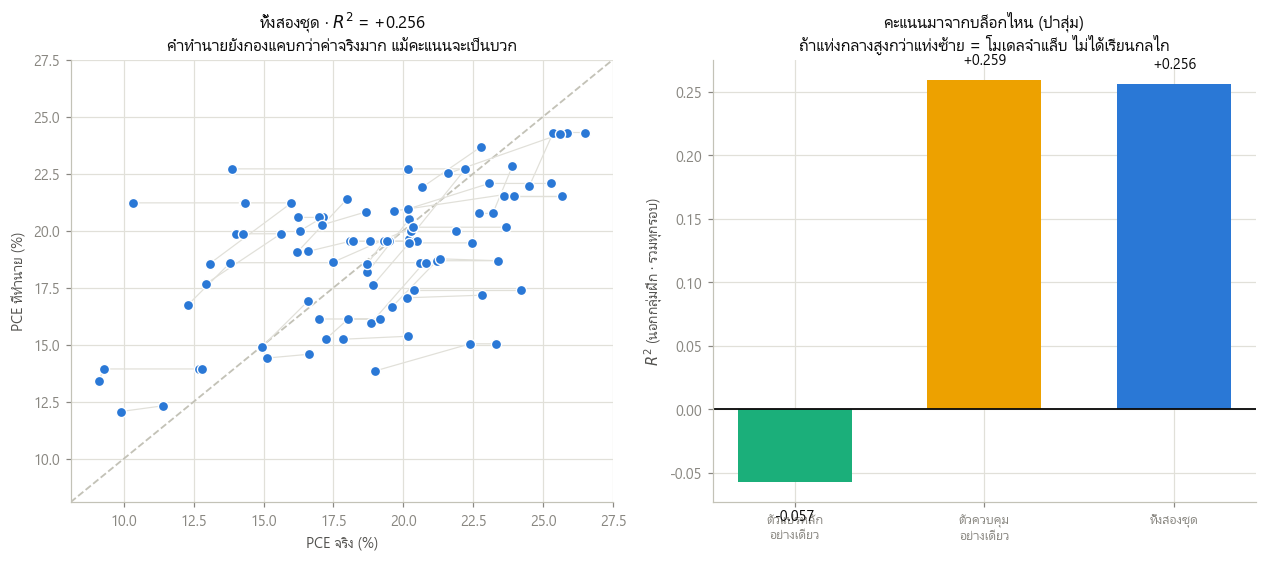

ช่วงของค่าจริง   9.1 – 26.5 %  (กว้าง 17.4)
ช่วงของคำทำนาย  12.1 – 24.3 %  (กว้าง 12.2)


In [5]:
BLOCKS = {"ตัวแปรหลักอย่างเดียว": MAIN, "ตัวควบคุมอย่างเดียว": CTRL, "ทั้งสองชุด": MAIN + CTRL}
COLS_OF = {k: [c for c in X.columns if OWNER[c] in v] for k, v in BLOCKS.items()}

res_abs, rows = {}, []
for name, mk in [("ป่าสุ่ม", make_rf), ("เชิงเส้น (Ridge)", make_ridge)]:
    for blk, feats in COLS_OF.items():
        d = oof("pce", mk, center=False, feats=feats)
        res_abs[(name, blk)] = d
        rows.append({"บล็อก": blk, **score(d, name)})
ABS1 = pd.DataFrame(rows)
display(ABS1.set_index(["แบบจำลอง", "บล็อก"])[["R2", "MAE", "RMSE", "n"]].round(3))
print("อ่านว่า: ถ้าแถว 'ตัวควบคุมอย่างเดียว' ทำคะแนนได้ แต่ 'ตัวแปรหลักอย่างเดียว' ทำไม่ได้")
print("        แปลว่าคะแนนรวมมาจากการจำว่าแล็บไหนเป็นคนทำ ไม่ใช่จากผลของการดัดแปลง")

d = res_abs[("ป่าสุ่ม", "ทั้งสองชุด")]
fig, axes = plt.subplots(1, 2, figsize=(11.6, 5.2))
ax = axes[0]
lo, hi = min(d.y.min(), d.pred.min()) - 1, max(d.y.max(), d.pred.max()) + 1
ax.plot([lo, hi], [lo, hi], color=BASE, lw=1.2, ls="--", zorder=1)
for p, g in d.groupby("paper"):
    ax.plot(g.y, g.pred, "-", color=GRID, lw=0.8, zorder=2)
ax.scatter(d.y, d.pred, s=44, color=C1, edgecolor="white", lw=0.9, zorder=3)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("PCE จริง (%)"); ax.set_ylabel("PCE ที่ทำนาย (%)")
ax.set_title(f"ทั้งสองชุด · $R^2$ = {score(d)['R2']:+.3f}\n"
             "คำทำนายยังกองแคบกว่าค่าจริงมาก แม้คะแนนจะเป็นบวก")

ax = axes[1]
b = ABS1[ABS1["แบบจำลอง"] == "ป่าสุ่ม"].set_index("บล็อก").loc[list(BLOCKS)]
col = [C3, C4, C1]
ax.bar(range(3), b["R2"], color=col, width=0.6)
ax.axhline(0, color=INK, lw=1.2)
ax.set_xticks(range(3), [k.replace("อย่างเดียว", "\nอย่างเดียว") for k in b.index], fontsize=8.8)
for i, v in enumerate(b["R2"]):
    ax.text(i, v + (0.012 if v >= 0 else -0.03), f"{v:+.3f}", ha="center", fontsize=9.5, color=INK)
ax.set_ylabel("$R^2$ (นอกกลุ่มฝึก · รวมทุกรอบ)")
ax.set_title("คะแนนมาจากบล็อกไหน (ป่าสุ่ม)\nถ้าแท่งกลางสูงกว่าแท่งซ้าย = โมเดลจำแล็บ ไม่ได้เรียนกลไก")
plt.tight_layout(); plt.show()

print(f"ช่วงของค่าจริง   {d.y.min():.1f} – {d.y.max():.1f} %  (กว้าง {d.y.max()-d.y.min():.1f})")
print(f"ช่วงของคำทำนาย  {d.pred.min():.1f} – {d.pred.max():.1f} %  (กว้าง {d.pred.max()-d.pred.min():.1f})")

### 3.2 ฝึก Voc · Jsc · FF แยกกัน แล้วคูณกลับเป็น PCE

แผนกำหนดไว้ว่าให้ทำแบบนี้ เหตุผลคือ $\text{PCE} = V_{oc}\cdot J_{sc}\cdot FF / P_{in}$ เป็นเอกลักษณ์ทางฟิสิกส์
(ตรวจกับข้อมูลจริงแล้วคลาดเคลื่อนค่ากลาง 0.04%) การให้โมเดลเรียนสามส่วนแยกกันแล้วประกอบคืน
จึงใส่ความรู้ฟิสิกส์เข้าไปฟรี ๆ และทำให้เห็นว่า **ผลไปตกที่ส่วนไหนของกราฟ J–V**

In [6]:
def oof_product(make_model, center=False):
    """ทำนาย voc · jsc · ff แยกกันแล้วประกอบคืนเป็น pce ตามเอกลักษณ์ PCE = Voc*Jsc*FF/100"""
    parts = {y: oof(y, make_model, center=center).set_index("device_id") for y in ["voc", "jsc", "ff"]}
    ids = set.intersection(*(set(p.index) for p in parts.values()))
    ids &= set(F.loc[F.pce.notna(), "device_id"])
    ids = sorted(ids)
    base = F.set_index("device_id").loc[ids]

    if center:  # บวกค่ากลางของเปเปอร์กลับก่อนคูณ แล้วค่อยลบออกอีกครั้งหลังคูณ
        pm = {y: base.groupby("paper")[y].transform("mean") for y in ["voc", "jsc", "ff"]}
        vhat = {y: parts[y].loc[ids, "pred"].values + pm[y].values for y in ["voc", "jsc", "ff"]}
    else:
        vhat = {y: parts[y].loc[ids, "pred"].values for y in ["voc", "jsc", "ff"]}

    pce_hat = vhat["voc"] * vhat["jsc"] * vhat["ff"] / 100
    d = pd.DataFrame({"device_id": ids, "paper": base["paper"].values,
                      "y": base["pce"].values, "pred": pce_hat})
    if center:
        d["y"] = d["y"] - d.groupby("paper")["y"].transform("mean")
        d["pred"] = d["pred"] - d.groupby("paper")["pred"].transform("mean")
    return d


rows = []
for name, mk in [("ป่าสุ่ม", make_rf), ("เชิงเส้น (Ridge)", make_ridge)]:
    for y in ["voc", "jsc", "ff"]:
        rows.append({"ทาง": f"แยกทีละส่วน ({name})", "ผลลัพธ์": y, **score(oof(y, mk), name)})
    rows.append({"ทาง": f"คูณกลับเป็น PCE ({name})", "ผลลัพธ์": "pce", **score(oof_product(mk), name)})
    rows.append({"ทาง": f"ทำนาย PCE ตรง ๆ ({name})", "ผลลัพธ์": "pce",
                 **score(res_abs[(name, "ทั้งสองชุด")], name)})
ABS2 = pd.DataFrame(rows)
display(ABS2.set_index(["ทาง", "ผลลัพธ์"])[["R2", "MAE", "RMSE", "n"]].round(3))
print("ทุกช่องยังวัดด้วยกติกาเดียวกัน: ตัดทีละเปเปอร์ · รวมคำทำนายทุกรอบมาคิดทีเดียว")

R2    MAE   RMSE   n
ทาง                                ผลลัพธ์                         
แยกทีละส่วน (ป่าสุ่ม)              voc      0.131  0.059  0.075  94
                                   jsc      0.424  1.198  1.531  94
                                   ff      -0.094  5.575  7.968  94
คูณกลับเป็น PCE (ป่าสุ่ม)          pce      0.264  2.747  3.457  93
ทำนาย PCE ตรง ๆ (ป่าสุ่ม)          pce      0.256  2.724  3.476  93
แยกทีละส่วน (เชิงเส้น (Ridge))     voc      0.044  0.064  0.078  94
                                   jsc      0.533  0.996  1.378  94
                                   ff      -0.188  5.992  8.303  94
คูณกลับเป็น PCE (เชิงเส้น (Ridge)) pce      0.236  2.936  3.523  93
ทำนาย PCE ตรง ๆ (เชิงเส้น (Ridge)) pce      0.208  2.966  3.586  93

ทุกช่องยังวัดด้วยกติกาเดียวกัน: ตัดทีละเปเปอร์ · รวมคำทำนายทุกรอบมาคิดทีเดียว


## 4. แบบจำลองที่ 2 — ทำนายส่วนต่างภายในเปเปอร์

เปลี่ยนคำถามจาก *"อุปกรณ์นี้ได้ PCE เท่าไร"* เป็น **_"ในบรรดาอุปกรณ์ของเปเปอร์นี้ ตัวไหนดีกว่าตัวไหน และดีกว่าเท่าไร"_**
ทำโดยลบค่ากลางของเปเปอร์ตัวเองออกจากผลลัพธ์ — วิธีเดียวกับ fixed effects ในเศรษฐมิติ

**ทำไมถึงตรงกับการใช้งานจริง**: แล็บที่จะเอาผลไปใช้ **มีอุปกรณ์ควบคุมของตัวเองอยู่แล้วเสมอ**
คำถามของเขาไม่เคยเป็น "อุปกรณ์ฉันจะได้กี่เปอร์เซ็นต์" แต่เป็น "ถ้าเติมสารนี้ ฉันจะดีขึ้นกว่าเดิมเท่าไร"

**สิ่งที่ได้ฟรีจากการลบค่ากลาง**: ทุกอย่างที่คงที่ทั้งเปเปอร์ถูกหักล้างหายไปหมด — สูตรเคมี ชนิด ETL
ความเร็วปั่น อุณหภูมิอบ จังหวะ antisolvent รวมถึง**สิ่งที่เราไม่ได้บันทึกไว้เลย** (ความชื้นในกล่อง ฝีมือคนทำ ยี่ห้อสารตั้งต้น)

จึงวัดทีละบล็อกเหมือน §3 เพื่อดู**ภาพสะท้อน**: บล็อกที่ทำคะแนนได้ใน §3 ควรกลายเป็นศูนย์ที่นี่ และกลับกัน
ถ้าออกมาแบบนั้นจริง แปลว่าการลบค่ากลางทำงานอย่างที่ควรเป็น — ไม่ใช่แค่เปลี่ยนตัวเลขให้ดูดีขึ้น

> **ผลข้างเคียงที่ต้องดูให้ออก**: หลังลบค่ากลาง ตัวควบคุมมีค่าคงที่ภายในเปเปอร์อยู่แล้ว
> มันจึงไม่เหลือข้อมูลใด ๆ แต่**ยังกินองศาอิสระและเพิ่มทางแตกกิ่งให้ต้นไม้** — การใส่มันไว้จึงอาจ*ลด*ความแม่น
> ตารางด้านล่างตอบตรง ๆ ว่าโมเดลสุดท้ายควรใส่หรือไม่ใส่

> **ข้อแลกเปลี่ยนที่ต้องประกาศ**: การลบค่ากลางของเปเปอร์ทดสอบต้องใช้ค่ากลางของเปเปอร์นั้น
> ตัวเลขนี้จึงตอบคำถาม "เรียงลำดับภายในเปเปอร์" ไม่ใช่ "ทำนายเปเปอร์ใหม่ทั้งฉบับจากศูนย์"
> ซึ่งเป็นสิ่งที่ §3 เพิ่งแสดงให้เห็นว่าทำไม่ได้ด้วยข้อมูลชุดนี้

R2    MAE   RMSE   n
แบบจำลอง         บล็อก                                         
ป่าสุ่ม          ตัวแปรหลักอย่างเดียว   0.178  1.083  1.491  93
                 ตัวควบคุมอย่างเดียว   -0.001  1.284  1.646  93
                 ทั้งสองชุด             0.142  1.126  1.524  93
                 คูณกลับจาก Voc·Jsc·FF  0.234  1.045  1.440  93
เชิงเส้น (Ridge) ตัวแปรหลักอย่างเดียว   0.173  1.096  1.496  93
                 ตัวควบคุมอย่างเดียว    0.000  1.282  1.645  93
                 ทั้งสองชุด             0.165  1.087  1.503  93
                 คูณกลับจาก Voc·Jsc·FF  0.143  1.126  1.523  93


ภาพสะท้อน (ป่าสุ่ม) — แนวทแยงสองเส้นนี้คือหลักฐานหลักของโน้ตบุ๊กทั้งเล่ม:


,§3 ทำนายค่าสัมบูรณ์,§4 ทำนายส่วนต่างในเปเปอร์
ตัวแปรหลักอย่างเดียว,-0.057,0.178
ตัวควบคุมอย่างเดียว,0.259,-0.001
ทั้งสองชุด,0.256,0.142


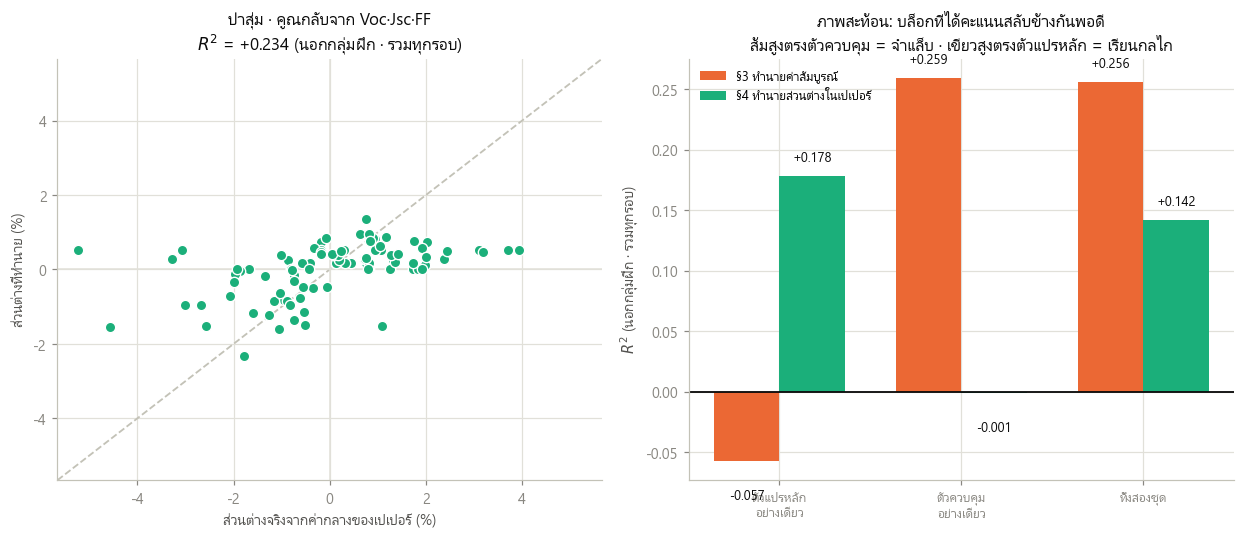

ชุดที่ดีที่สุดหลังลบค่ากลาง: ป่าสุ่ม · คูณกลับจาก Voc·Jsc·FF
  -> โมเดลสุดท้ายที่ใช้ใน §5 เป็นต้นไปคือชุดนี้


In [7]:
rows, res_ctr = [], {}
for name, mk in [("ป่าสุ่ม", make_rf), ("เชิงเส้น (Ridge)", make_ridge)]:
    for blk, feats in COLS_OF.items():
        d = oof("pce", mk, center=True, feats=feats)
        res_ctr[(name, blk)] = d
        rows.append({"บล็อก": blk, **score(d, name)})
    d = oof_product(mk, center=True)
    res_ctr[(name, "คูณกลับจาก Voc·Jsc·FF")] = d
    rows.append({"บล็อก": "คูณกลับจาก Voc·Jsc·FF", **score(d, name)})
CTR1 = pd.DataFrame(rows)
display(CTR1.set_index(["แบบจำลอง", "บล็อก"])[["R2", "MAE", "RMSE", "n"]].round(3))

CMP = pd.DataFrame({
    "§3 ทำนายค่าสัมบูรณ์": [score(res_abs[("ป่าสุ่ม", b)])["R2"] for b in BLOCKS],
    "§4 ทำนายส่วนต่างในเปเปอร์": [score(res_ctr[("ป่าสุ่ม", b)])["R2"] for b in BLOCKS],
}, index=list(BLOCKS))
print("\nภาพสะท้อน (ป่าสุ่ม) — แนวทแยงสองเส้นนี้คือหลักฐานหลักของโน้ตบุ๊กทั้งเล่ม:")
display(CMP.round(3))

best = max(res_ctr, key=lambda k: score(res_ctr[k])["R2"])
d = res_ctr[best]
fig, axes = plt.subplots(1, 2, figsize=(11.4, 5.0))
ax = axes[0]
lim = max(abs(d.y).max(), abs(d.pred).max()) * 1.08
ax.plot([-lim, lim], [-lim, lim], color=BASE, lw=1.2, ls="--", zorder=1)
ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
ax.scatter(d.y, d.pred, s=46, color=C3, edgecolor="white", lw=0.9, zorder=3)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("ส่วนต่างจริงจากค่ากลางของเปเปอร์ (%)"); ax.set_ylabel("ส่วนต่างที่ทำนาย (%)")
ax.set_title(f"{best[0]} · {best[1]}\n$R^2$ = {score(d)['R2']:+.3f} (นอกกลุ่มฝึก · รวมทุกรอบ)")

ax = axes[1]
w, xs = 0.36, np.arange(len(BLOCKS))
ax.bar(xs - w / 2, CMP["§3 ทำนายค่าสัมบูรณ์"], w, color=C2, label="§3 ทำนายค่าสัมบูรณ์")
ax.bar(xs + w / 2, CMP["§4 ทำนายส่วนต่างในเปเปอร์"], w, color=C3, label="§4 ทำนายส่วนต่างในเปเปอร์")
ax.axhline(0, color=INK, lw=1.2)
ax.set_xticks(xs, [k.replace("อย่างเดียว", "\nอย่างเดียว") for k in CMP.index], fontsize=8.6)
for i in range(len(CMP)):
    for off, c in [(-w / 2, "§3 ทำนายค่าสัมบูรณ์"), (w / 2, "§4 ทำนายส่วนต่างในเปเปอร์")]:
        v = CMP[c].iloc[i]
        ax.text(i + off, v + (0.012 if v >= 0 else -0.032), f"{v:+.3f}", ha="center", fontsize=8.4, color=INK)
ax.set_ylabel("$R^2$ (นอกกลุ่มฝึก · รวมทุกรอบ)")
ax.legend(frameon=False, fontsize=8.4)
ax.set_title("ภาพสะท้อน: บล็อกที่ได้คะแนนสลับข้างกันพอดี\nส้มสูงตรงตัวควบคุม = จำแล็บ · เขียวสูงตรงตัวแปรหลัก = เรียนกลไก")
plt.tight_layout(); plt.show()

BEST_MODEL, BEST_SET = best
print(f"ชุดที่ดีที่สุดหลังลบค่ากลาง: {BEST_MODEL} · {BEST_SET}")
print(f"  -> โมเดลสุดท้ายที่ใช้ใน §5 เป็นต้นไปคือชุดนี้")

## 5. ตัวแปรไหนมีน้ำหนัก — SHAP คู่กับการตัดตัวแปรออก

รายงานแผนไว้ที่ SHAP แต่ SHAP ตอบคำถามเดียวคือ *"โมเดลที่ฝึกเสร็จแล้วใช้ตัวแปรนี้ยังไง"*
มันไม่ได้บอกว่าตัวแปรนั้น**ช่วยทำนายเปเปอร์ที่ไม่เคยเห็นจริงหรือเปล่า** จึงวัดคู่กันสองแบบ

| วิธี | คำถามที่ตอบ | คำนวณจาก |
|---|---|---|
| **SHAP** | ตัวแปรผลักคำทำนายไปทางไหน แรงแค่ไหน รายอุปกรณ์ | `TreeExplainer` บนป่าที่ฝึกด้วยข้อมูลทั้งหมด |
| **ตัดตัวแปรออก** | ถ้าไม่มีตัวแปรนี้ ความแม่นนอกกลุ่มฝึกตกลงเท่าไร | เทรนใหม่ทั้ง LOPO โดยไม่มีตัวแปรนั้น แล้วเทียบ $R^2$ |

ตัดออกทั้ง**กลุ่ม** ของตัวแปรเดียวกัน (ทุกคอลัมน์ one-hot ของ `htl_mod_kind` ไปพร้อมกัน)
เพราะการวัดทีละคอลัมน์ย่อยจะกระจายเครดิตของตัวแปรเดียวออกเป็นหลายชิ้นจนอ่านผิด

,SHAP_เฉลี่ย,R2_ที่หายถ้าตัดออก,บทบาท
htl_mod_kind,0.7223,0.1552,ตัวแปรหลัก
htl_route,0.1392,-0.0166,ตัวแปรหลัก
htl_dope,0.1035,0.0337,ตัวแปรหลัก
etl_family,0.0954,0.0167,ตัวควบคุม
x_Br,0.0936,0.0141,ตัวควบคุม
a_FA,0.0699,0.0192,ตัวควบคุม
a_Cs,0.0332,-0.0014,ตัวควบคุม


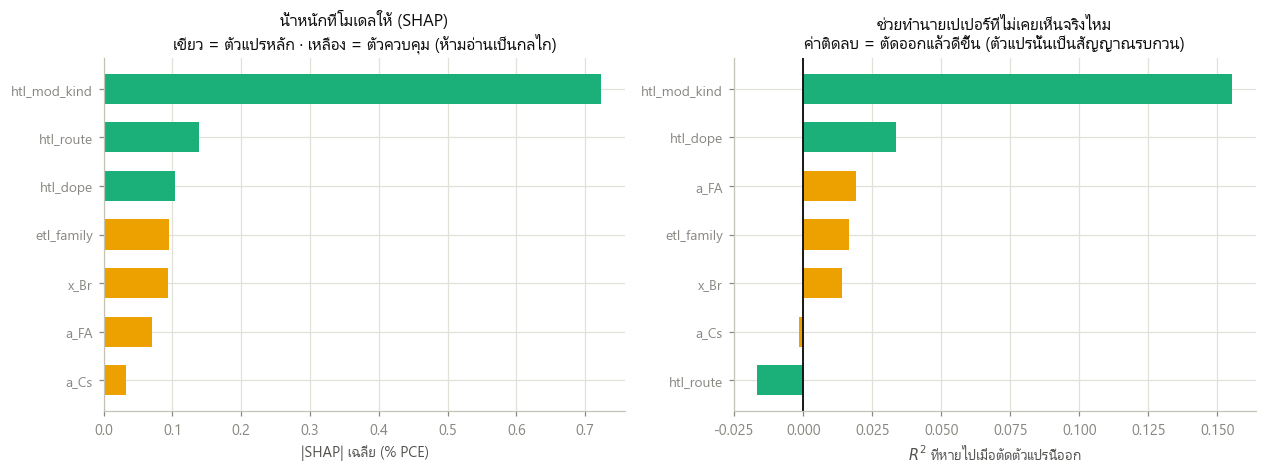

In [8]:
keep = F["pce"].notna().values
Xk = X[keep]
yc = paper_center(F.loc[keep, "pce"].values, G[keep], F.loc[keep, "device_id"].values).values

rf_full = make_rf().fit(Xk, yc)
SV = shap.TreeExplainer(rf_full).shap_values(Xk)
shap_col = pd.Series(np.abs(SV).mean(axis=0), index=Xk.columns)
shap_var = shap_col.groupby(shap_col.index.map(OWNER)).sum()

r2_full = score(oof("pce", make_rf, center=True))["R2"]
drop = {}
for v in MAIN + CTRL:
    feats = [c for c in X.columns if OWNER[c] != v]
    drop[v] = r2_full - score(oof("pce", make_rf, center=True, feats=feats))["R2"]

IMP = (pd.DataFrame({"SHAP_เฉลี่ย": shap_var, "R2_ที่หายถ้าตัดออก": pd.Series(drop)})
       .assign(บทบาท=lambda t: ["ตัวแปรหลัก" if i in MAIN else "ตัวควบคุม" for i in t.index])
       .sort_values("SHAP_เฉลี่ย", ascending=False))
display(IMP.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4))
o = IMP.sort_values("SHAP_เฉลี่ย")
cols = [C3 if b == "ตัวแปรหลัก" else C4 for b in o.บทบาท]
axes[0].barh(range(len(o)), o["SHAP_เฉลี่ย"], color=cols, height=0.62)
axes[0].set_yticks(range(len(o)), o.index, fontsize=9)
axes[0].set_xlabel("|SHAP| เฉลี่ย (% PCE)")
axes[0].set_title("น้ำหนักที่โมเดลให้ (SHAP)\nเขียว = ตัวแปรหลัก · เหลือง = ตัวควบคุม (ห้ามอ่านเป็นกลไก)")
o2 = IMP.sort_values("R2_ที่หายถ้าตัดออก")
axes[1].barh(range(len(o2)), o2["R2_ที่หายถ้าตัดออก"],
             color=[C3 if b == "ตัวแปรหลัก" else C4 for b in o2.บทบาท], height=0.62)
axes[1].axvline(0, color=INK, lw=1.2)
axes[1].set_yticks(range(len(o2)), o2.index, fontsize=9)
axes[1].set_xlabel("$R^2$ ที่หายไปเมื่อตัดตัวแปรนี้ออก")
axes[1].set_title("ช่วยทำนายเปเปอร์ที่ไม่เคยเห็นจริงไหม\nค่าติดลบ = ตัดออกแล้วดีขึ้น (ตัวแปรนั้นเป็นสัญญาณรบกวน)")
plt.tight_layout(); plt.show()

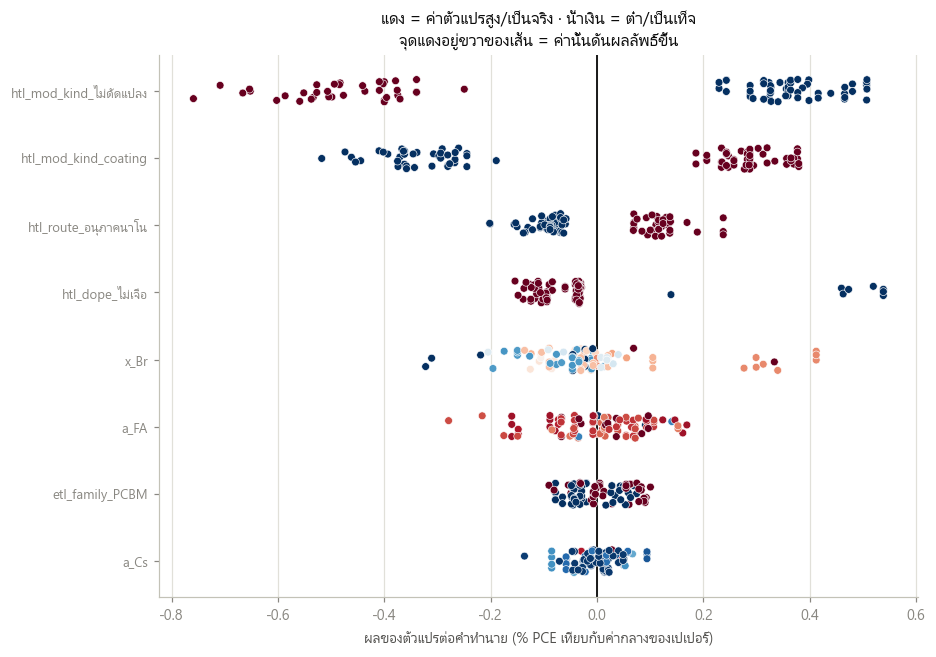

In [9]:
# ทิศทางของผล -- SHAP รายอุปกรณ์ของคอลัมน์ที่แรงที่สุด
top = shap_col.sort_values(ascending=False).head(8).index[::-1]
fig, ax = plt.subplots(figsize=(8.6, 0.52 * len(top) + 1.9))
rng = np.random.default_rng(SEED)
for i, c in enumerate(top):
    s, v = SV[:, list(Xk.columns).index(c)], Xk[c].values
    vn = (v - np.nanmin(v)) / (np.ptp(v) or 1)
    ax.scatter(s, i + rng.uniform(-0.17, 0.17, len(s)), s=26,
               c=vn, cmap="RdBu_r", vmin=0, vmax=1, edgecolor="white", lw=0.4, zorder=3)
ax.axvline(0, color=INK, lw=1.2)
ax.set_yticks(range(len(top)), [short(c, 34) for c in top], fontsize=8.6)
ax.set_xlabel("ผลของตัวแปรต่อคำทำนาย (% PCE เทียบกับค่ากลางของเปเปอร์)")
ax.set_title("แดง = ค่าตัวแปรสูง/เป็นจริง · น้ำเงิน = ต่ำ/เป็นเท็จ\nจุดแดงอยู่ขวาของเส้น = ค่านั้นดันผลลัพธ์ขึ้น")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. จัดอันดับกลุ่มสารบนสนามเดียวกัน

จุดขายข้อ 3 ของงาน: เปเปอร์เดี่ยวมีสารเดียว จึงเทียบข้ามตระกูลสารไม่ได้เลยโดยธรรมชาติ

วัดโดยเทียบแต่ละกลุ่มสารกับ**อุปกรณ์ควบคุมในเปเปอร์เดียวกัน**เท่านั้น แล้วรวมผลระดับเปเปอร์
หน่วยของช่วงความเชื่อมั่นจึงเป็น *เปเปอร์* ไม่ใช่ *อุปกรณ์* — ไม่เกิดการนับตัวอย่างซ้ำ

,เปเปอร์,ΔPCE_ค่ากลาง,CI95_ล่าง,CI95_บน,ทิศบวก,p
กลุ่มสาร,,,,,,
SAM (คาร์บาโซล),7,4.000,3.520,4.505,7/7,0.0156
** รวมทุกกลุ่ม **,22,1.995,1.524,2.500,21/22,0.0000
โมเลกุลอินทรีย์,11,1.900,1.500,2.367,10/11,0.0117
เกลือไอออน,6,0.811,0.558,1.488,6/6,0.0312


แถวรวมยุบจาก 24 แถว (เปเปอร์ x กลุ่มสาร) เหลือ 22 เปเปอร์ -- 2 เปเปอร์ทดสอบมากกว่าหนึ่งกลุ่มสาร จึงต้องยุบก่อนไม่ให้นับซ้ำ
กลุ่มสารที่ไม่มีแถว: ['ออกไซด์'] -- ไม่ใช่ว่าไม่มีข้อมูล แต่เปเปอร์ที่ใช้สารกลุ่มนี้ ไม่มีอุปกรณ์ควบคุมของตัวเอง จึงไม่มีคู่เทียบภายในเปเปอร์


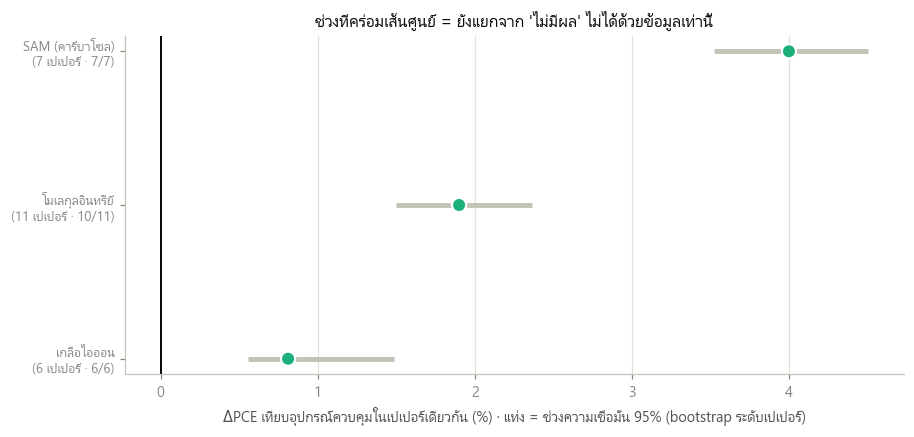

⚠️ กลุ่มที่มีเปเปอร์น้อยกว่า 3 ฉบับ ช่วงความเชื่อมั่นจะกว้างมากจนใช้จัดอันดับไม่ได้ — อ่านเป็นข้อสังเกตเท่านั้น


In [10]:
def paper_contrasts(col, ycols=("pce", "ff", "voc", "jsc", "vtfl", "trap_density",
                                "contact_angle", "grain_size", "afm_rms", "vbm",
                                "work_function", "hi", "retention_25c", "degradation_rate")):
    """ผลต่างเทียบอุปกรณ์ควบคุมในเปเปอร์เดียวกัน -> หนึ่งแถวต่อ (เปเปอร์, ระดับ)"""
    out = []
    for p, g in F.groupby("paper"):
        ctrl = g[g.htl_mod_kind == "ไม่ดัดแปลง"]
        if ctrl.empty:
            continue
        for lv, sub in g[g.htl_mod_kind != "ไม่ดัดแปลง"].groupby(col):
            rec = dict(paper=p, ระดับ=lv, n_treated=len(sub))
            for y in ycols:
                b, o = ctrl[y].mean(), sub[y].mean()
                rec["Δ" + y] = o - b if pd.notna(b) and pd.notna(o) else np.nan
            out.append(rec)
    return pd.DataFrame(out)


CLS = paper_contrasts("htl_mod_class")
rows = []
for lv, g in CLS.groupby("ระดับ"):
    v = g["Δpce"].dropna()
    lo, hi = boot_ci(v)
    p, k, n = sign_test(v)
    rows.append(dict(กลุ่มสาร=lv, เปเปอร์=len(v), ΔPCE_ค่ากลาง=round(float(v.median()), 3),
                     CI95_ล่าง=round(lo, 3) if pd.notna(lo) else np.nan,
                     CI95_บน=round(hi, 3) if pd.notna(hi) else np.nan,
                     ทิศบวก=f"{k}/{n}", p=round(p, 4) if pd.notna(p) else np.nan))
# แถวรวม: ต้องยุบเป็นค่าเดียวต่อเปเปอร์ก่อน -- 3 เปเปอร์ทดสอบมากกว่าหนึ่งกลุ่มสาร
# ถ้าเอา 25 แถว (เปเปอร์ x กลุ่มสาร) มาคิดตรง ๆ จะนับเปเปอร์เหล่านั้นซ้ำ
v = CLS.groupby("paper")["Δpce"].mean().dropna()
lo, hi = boot_ci(v); p, k, n = sign_test(v)
rows.append(dict(กลุ่มสาร="** รวมทุกกลุ่ม **", เปเปอร์=len(v), ΔPCE_ค่ากลาง=round(float(v.median()), 3),
                 CI95_ล่าง=round(lo, 3), CI95_บน=round(hi, 3), ทิศบวก=f"{k}/{n}", p=round(p, 4)))
RANK = pd.DataFrame(rows).sort_values("ΔPCE_ค่ากลาง", ascending=False)
display(RANK.set_index("กลุ่มสาร"))
print(f"แถวรวมยุบจาก {len(CLS)} แถว (เปเปอร์ x กลุ่มสาร) เหลือ {len(v)} เปเปอร์ "
      f"-- {len(CLS) - CLS.paper.nunique()} เปเปอร์ทดสอบมากกว่าหนึ่งกลุ่มสาร จึงต้องยุบก่อนไม่ให้นับซ้ำ")

_no_ctrl = sorted(set(F.loc[F.htl_mod_class != "ไม่ดัดแปลง", "htl_mod_class"]) - set(CLS["ระดับ"]))
if _no_ctrl:
    print(f"กลุ่มสารที่ไม่มีแถว: {_no_ctrl} -- ไม่ใช่ว่าไม่มีข้อมูล แต่เปเปอร์ที่ใช้สารกลุ่มนี้"
          f" ไม่มีอุปกรณ์ควบคุมของตัวเอง จึงไม่มีคู่เทียบภายในเปเปอร์")

r = RANK[RANK.กลุ่มสาร != "** รวมทุกกลุ่ม **"].sort_values("ΔPCE_ค่ากลาง")
fig, ax = plt.subplots(figsize=(8.4, 0.62 * len(r) + 2.2))
y = np.arange(len(r))
ax.hlines(y, r.CI95_ล่าง, r.CI95_บน, color=BASE, lw=3.2, zorder=2)
ax.scatter(r.ΔPCE_ค่ากลาง, y, s=86, color=[C3 if v > 0 else C2 for v in r.ΔPCE_ค่ากลาง],
           edgecolor="white", lw=1.4, zorder=3)
ax.axvline(0, color=INK, lw=1.3)
ax.set_yticks(y, [f"{a}\n({int(b)} เปเปอร์ · {c})" for a, b, c in zip(r.กลุ่มสาร, r.เปเปอร์, r.ทิศบวก)], fontsize=8.6)
ax.set_xlabel("ΔPCE เทียบอุปกรณ์ควบคุมในเปเปอร์เดียวกัน (%) · แท่ง = ช่วงความเชื่อมั่น 95% (bootstrap ระดับเปเปอร์)")
ax.set_title("ช่วงที่คร่อมเส้นศูนย์ = ยังแยกจาก 'ไม่มีผล' ไม่ได้ด้วยข้อมูลเท่านี้")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("⚠️ กลุ่มที่มีเปเปอร์น้อยกว่า 3 ฉบับ ช่วงความเชื่อมั่นจะกว้างมากจนใช้จัดอันดับไม่ได้ — อ่านเป็นข้อสังเกตเท่านั้น")

## 7. กลไก — ผลวิ่งผ่านการลดกับดักพาหะเป็นสัดส่วนเท่าไร

ส่วนที่ใหม่ที่สุดของงาน และเป็นสิ่งที่เปเปอร์เดี่ยวทำไม่ได้ สมมุติฐาน:

$$\text{ดัดแปลงผิว HTL} \;\xrightarrow{\;a\;}\; \text{VTFL ลด (กับดักน้อยลง)} \;\xrightarrow{\;b\;}\; \text{PCE ขึ้น}$$

วัดทั้งสามข้อต่อ**ภายในเปเปอร์**แล้วรวมระดับเปเปอร์ ตามสูตร product-of-coefficients:

| สัญลักษณ์ | คืออะไร | วัดยังไง |
|---|---|---|
| $c$ | ผลรวมทั้งหมด | ค่ากลางของ ΔPCE รายเปเปอร์ |
| $a$ | ข้อต่อแรก | ค่ากลางของ ΔVTFL รายเปเปอร์ |
| $b$ | ข้อต่อสอง | ความชันของ ΔPCE ต่อ ΔVTFL ข้ามเปเปอร์ (ผ่านจุดกำเนิด) |
| $ab/c$ | สัดส่วนที่วิ่งผ่านกลไกนี้ | ที่เหลือคือทางอื่น (ผิวสัมผัส · การจัดเรียงระดับพลังงาน · สัณฐานฟิล์ม) |

> เปเปอร์ที่วัด VTFL มีไม่ถึงสิบฉบับ ตัวเลขนี้จึงเป็น **การประมาณขนาด ไม่ใช่การพิสูจน์**
> ช่วงความเชื่อมั่นด้านล่างสะท้อนความไม่แน่นอนนั้นตรง ๆ

เปเปอร์ที่มีคู่เทียบและวัด PCE: 22 · ที่วัด VTFL ด้วย: 13


,ค่า,หน่วย
ปริมาณ,,
c · ผลรวมทั้งหมด (ΔPCE),2.367,% PCE
a · ข้อต่อแรก (ΔVTFL),-0.145,V
b · ข้อต่อสอง (ΔPCE ต่อ ΔVTFL),-10.505,% PCE ต่อ V
a·b · ผลที่วิ่งผ่านกับดัก,1.523,% PCE
c − a·b · ผลที่ไปทางอื่น,0.843,% PCE
สัดส่วนที่ผ่านกับดัก,64%,CI95 21% – 107%



ข้อต่อแรก : VTFL ลดลงใน 13/13 เปเปอร์ที่วัด (sign test p = 0.0002)
ข้อต่อสอง : ΔVTFL กับ ΔPCE สหสัมพันธ์อันดับ +0.35 (n = 13 เปเปอร์)
ผลรวม    : PCE เพิ่มขึ้นใน 21/22 เปเปอร์ (sign test p = 0.0000)


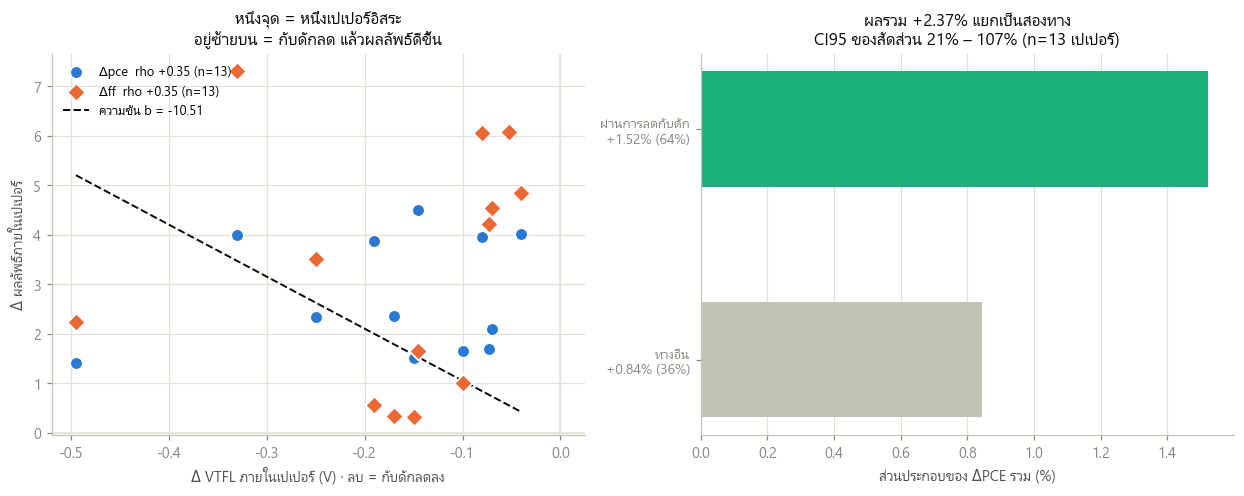

In [11]:
MED = paper_contrasts("htl_mod_kind")
M = MED.groupby("paper")[["Δpce", "Δvtfl", "Δff", "Δvoc"]].mean().dropna(subset=["Δpce"])
both = M.dropna(subset=["Δvtfl"])
print(f"เปเปอร์ที่มีคู่เทียบและวัด PCE: {len(M)} · ที่วัด VTFL ด้วย: {len(both)}")


def mediation(dfm):
    c = float(dfm["Δpce"].median())
    a = float(dfm["Δvtfl"].median())
    x, y = dfm["Δvtfl"].values, dfm["Δpce"].values
    b = float((x * y).sum() / (x * x).sum()) if (x * x).sum() > 0 else np.nan
    return c, a, b, a * b, (a * b / c if c else np.nan)


c, a, b, ab, prop = mediation(both)
rng = np.random.default_rng(SEED)
props, abs_ = [], []
for _ in range(4000):
    s = both.iloc[rng.integers(0, len(both), len(both))]
    if s["Δvtfl"].nunique() < 2:
        continue
    _c, _a, _b, _ab, _p = mediation(s)
    if pd.notna(_p):
        props.append(_p); abs_.append(_ab)

MEDTBL = pd.DataFrame([
    dict(ปริมาณ="c · ผลรวมทั้งหมด (ΔPCE)", ค่า=round(c, 3), หน่วย="% PCE"),
    dict(ปริมาณ="a · ข้อต่อแรก (ΔVTFL)", ค่า=round(a, 4), หน่วย="V"),
    dict(ปริมาณ="b · ข้อต่อสอง (ΔPCE ต่อ ΔVTFL)", ค่า=round(b, 3), หน่วย="% PCE ต่อ V"),
    dict(ปริมาณ="a·b · ผลที่วิ่งผ่านกับดัก", ค่า=round(ab, 3), หน่วย="% PCE"),
    dict(ปริมาณ="c − a·b · ผลที่ไปทางอื่น", ค่า=round(c - ab, 3), หน่วย="% PCE"),
    dict(ปริมาณ="สัดส่วนที่ผ่านกับดัก", ค่า=f"{prop:.0%}", หน่วย=f"CI95 {np.percentile(props,2.5):.0%} – {np.percentile(props,97.5):.0%}"),
])
display(MEDTBL.set_index("ปริมาณ"))

_p, _k, _n = sign_test(both["Δvtfl"])
print(f"\nข้อต่อแรก : VTFL ลดลงใน {_n - _k}/{_n} เปเปอร์ที่วัด (sign test p = {_p:.4f})")
_r, _n2 = spearman(both["Δvtfl"], both["Δpce"])
print(f"ข้อต่อสอง : ΔVTFL กับ ΔPCE สหสัมพันธ์อันดับ {_r:+.2f} (n = {_n2} เปเปอร์)")
_p3, _k3, _n3 = sign_test(M["Δpce"])
print(f"ผลรวม    : PCE เพิ่มขึ้นใน {_k3}/{_n3} เปเปอร์ (sign test p = {_p3:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.6))
ax = axes[0]
for y_, cc, mk in [("Δpce", C1, "o"), ("Δff", C2, "D")]:
    dd = both.dropna(subset=[y_])
    r_, n_ = spearman(dd["Δvtfl"], dd[y_])
    ax.scatter(dd["Δvtfl"], dd[y_], s=68, color=cc, marker=mk, edgecolor="white", lw=1.1,
               label=f"{y_}  rho {r_:+.2f} (n={n_})", zorder=3)
xs = np.linspace(both["Δvtfl"].min(), both["Δvtfl"].max(), 20)
ax.plot(xs, b * xs, color=INK, lw=1.3, ls="--", zorder=2, label=f"ความชัน b = {b:+.2f}")
ax.axvline(0, color=GRID, lw=1); ax.axhline(0, color=GRID, lw=1)
ax.set_xlabel("Δ VTFL ภายในเปเปอร์ (V) · ลบ = กับดักลดลง")
ax.set_ylabel("Δ ผลลัพธ์ภายในเปเปอร์")
ax.legend(frameon=False, fontsize=8.4)
ax.set_title("หนึ่งจุด = หนึ่งเปเปอร์อิสระ\nอยู่ซ้ายบน = กับดักลด แล้วผลลัพธ์ดีขึ้น")

ax = axes[1]
ax.barh([1, 0], [ab, c - ab], color=[C3, BASE], height=0.5)
ax.set_yticks([1, 0], [f"ผ่านการลดกับดัก\n{ab:+.2f}% ({prop:.0%})",
                       f"ทางอื่น\n{c-ab:+.2f}% ({1-prop:.0%})"], fontsize=9)
ax.axvline(0, color=INK, lw=1.2)
ax.set_xlabel("ส่วนประกอบของ ΔPCE รวม (%)")
ax.set_title(f"ผลรวม {c:+.2f}% แยกเป็นสองทาง\nCI95 ของสัดส่วน {np.percentile(props,2.5):.0%} – {np.percentile(props,97.5):.0%} (n={len(both)} เปเปอร์)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 7.2 ผลวิ่งผ่านกี่ช่องทาง — และแยกจากกันได้ไหม

§7 สมมุติว่ามีช่องทางเดียว (ลด trap → ผลลัพธ์ดีขึ้น) แต่ข้อสมมุตินั้นตรวจสอบได้ตรง ๆ:
**ถ้ามีช่องทางเดียวจริง องค์ประกอบทั้งสามของ PCE ต้องขึ้นลงพร้อมกัน**

ถ้า ΔFF กับ ΔJsc ไม่สัมพันธ์กันเลย แปลว่ามี **อย่างน้อยสองกลไกที่เป็นอิสระต่อกัน** และการรายงาน
"สัดส่วนที่ผ่านกับดัก" ตัวเดียวก็ปิดบังโครงสร้างนั้นไว้

| ช่องทางที่คาด | ตัวกลางที่วัดได้ | ควรดัน |
|---|---|---|
| **อิเล็กทรอนิกส์** — กับดักที่รอยต่อลดลง | `vtfl` · `trap_density` | FF (และ Voc) |
| **สัณฐาน** — ผิว HTL เปลี่ยนสมบัติการเปียก → การตกผลึกของเพอรอฟสไกต์เปลี่ยน | `contact_angle` · `grain_size` | Jsc |

**ตั้งใจไม่ระบุทิศทางของช่องสัณฐานไว้ล่วงหน้า** เพราะวรรณกรรมมีสองแรงที่ดันคนละทาง —
ผิวเปียกขึ้นให้ฟิล์มคลุมสม่ำเสมอกว่า แต่ผิวไม่ชอบน้ำให้จุดก่อผลึกน้อยลงจนได้เกรนใหญ่ขึ้น
ข้อมูลจะเป็นตัวบอกเองว่าแรงไหนชนะ

`contact_angle` กับ `grain_size` เพิ่งถูกดึงเข้า `target_table` (แก้ที่ `recheck_comlumn_preapare` §mediator
แล้ว regenerate ตามกติกาของโปรเจกต์ — ไม่ได้แก้ปลายทาง) เดิมสองตัวนี้อยู่ในด่านตรวจชื่อแต่ไม่เคยถูก pivot ออกมา

> **เกณฑ์แบ่งช่องทางเป็นเส้นที่เราตั้งเอง** จึงต้องพิสูจน์ว่าข้อสรุปไม่ได้มาจากการเลือกเส้น
> หลักฐานหลักคือ **สหสัมพันธ์ ΔFF↔ΔJsc ซึ่งไม่ต้องใช้เกณฑ์ใด ๆ เลย** ส่วนตารางแบ่งกลุ่มเป็นภาพประกอบ
> และมีการทดสอบความไวต่อเกณฑ์กำกับไว้ด้านล่าง

ถ้าเป็นช่องทางเดียว องค์ประกอบต้องขึ้นลงพร้อมกัน -- สหสัมพันธ์อันดับข้ามเปเปอร์:


,rho,n_paper
คู่,,
Δff ↔ Δjsc,-0.02,22
Δff ↔ Δvoc,-0.25,22
Δjsc ↔ Δvoc,0.57,22
Δvtfl ↔ Δff,0.35,13
Δvtfl ↔ Δjsc,0.21,13
Δvtfl ↔ Δvoc,-0.08,13
Δcontact_angle ↔ Δjsc,0.65,11
Δcontact_angle ↔ Δff,-0.10,11
Δgrain_size ↔ Δjsc,0.40,4


,จำนวนเปเปอร์
ช่องทาง,
ทั้งสองช่อง,11
ช่อง Jsc อย่างเดียว,5
ช่อง FF อย่างเดียว,5
ไม่ขยับทั้งคู่,1



ความไวต่อเกณฑ์ (ข้อสรุปต้องไม่พลิกเมื่อขยับเส้นแบ่ง):
  เกณฑ์ 0.5%: FF อย่างเดียว 1 · Jsc อย่างเดียว 3 · ทั้งคู่ 17
  เกณฑ์ 1.0%: FF อย่างเดียว 5 · Jsc อย่างเดียว 5 · ทั้งคู่ 11
  เกณฑ์ 2.0%: FF อย่างเดียว 6 · Jsc อย่างเดียว 6 · ทั้งคู่ 7
  เกณฑ์ 3.0%: FF อย่างเดียว 5 · Jsc อย่างเดียว 6 · ทั้งคู่ 5

ส่วนแบ่งของการเพิ่ม PCE (ค่ากลาง): VOC 32% · JSC 31% · FF 36%


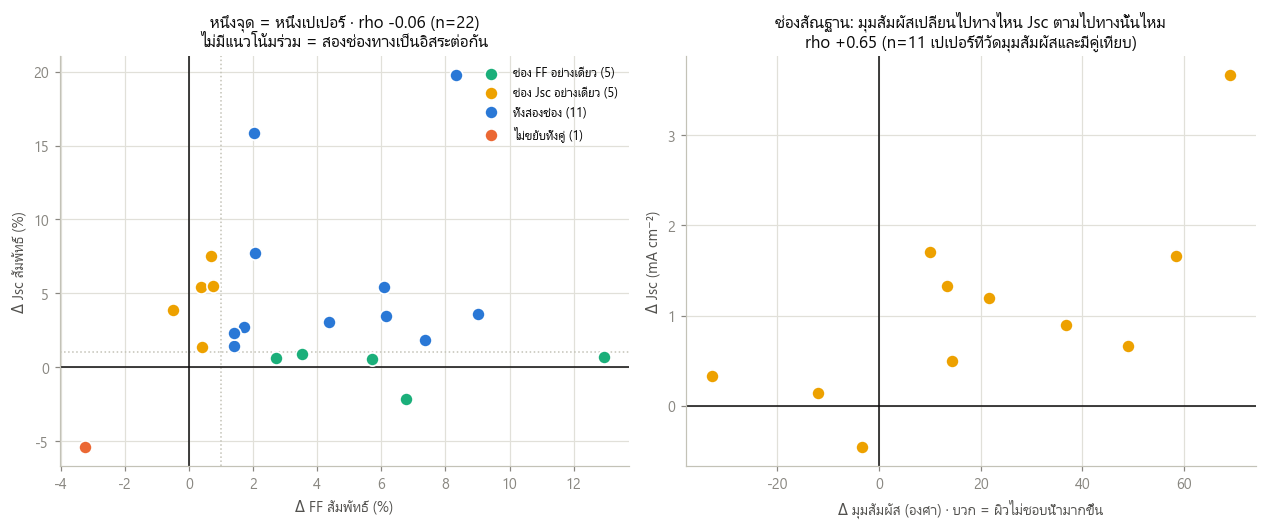


ตัวกลางแต่ละตัวเจาะจงกับช่องทางของตัวเอง -- นี่คือหลักฐานว่าสองช่องแยกกันจริง:
  VTFL          เกาะกับ ΔFF  +0.35  แต่กับ ΔVoc -0.08
  มุมสัมผัส      เกาะกับ ΔJsc +0.65  แต่กับ ΔFF  -0.10
ถ้าเป็นกลไกเดียวกัน ตัวกลางทั้งสองต้องเกาะกับทุกองค์ประกอบพอ ๆ กัน ซึ่งไม่ใช่

ทิศทางที่ข้อมูลบอก (ไม่ใช่ที่เราตั้งไว้ล่วงหน้า):
  มุมสัมผัสเพิ่มขึ้นใน 8/11 เปเปอร์ (ค่ากลาง +14.3 องศา)
  และเปเปอร์ที่มุมสัมผัสเพิ่มมาก คือเปเปอร์ที่ Jsc เพิ่มมาก (rho +0.65)
  ขนาดเกรนเพิ่มขึ้น 4/4 เปเปอร์ (ค่ากลาง +68 nm) -- n น้อยมาก
  -> อ่านได้ว่า 'ผิวไม่ชอบน้ำขึ้น -> จุดก่อผลึกน้อยลง -> เกรนใหญ่ขึ้น -> Jsc ขึ้น'
     แต่นี่เป็น *การตีความ* ที่สอดคล้องกับวรรณกรรม ไม่ใช่สิ่งที่ข้อมูลชุดนี้พิสูจน์
     ข้อต่อ 'เกรนใหญ่ขึ้น' ยืนบน 4 เปเปอร์เท่านั้น -- คือช่องว่างที่ควรเก็บข้อมูลเพิ่ม


In [12]:
CH = paper_contrasts("htl_mod_kind")
# ดึงทุกคอลัมน์ Δ แบบอัตโนมัติ -- ถ้าระบุชื่อไว้ตายตัว ตัวกลางที่เพิ่มใหม่จะหายเงียบ
CHP = CH.groupby("paper")[[c for c in CH.columns if c.startswith("Δ")]].mean()

print("ถ้าเป็นช่องทางเดียว องค์ประกอบต้องขึ้นลงพร้อมกัน -- สหสัมพันธ์อันดับข้ามเปเปอร์:")
rows = []
for a, b in [("Δff", "Δjsc"), ("Δff", "Δvoc"), ("Δjsc", "Δvoc"),
             ("Δvtfl", "Δff"), ("Δvtfl", "Δjsc"), ("Δvtfl", "Δvoc"),
             ("Δcontact_angle", "Δjsc"), ("Δcontact_angle", "Δff"), ("Δgrain_size", "Δjsc")]:
    r, n = spearman(CHP[a], CHP[b])
    rows.append(dict(คู่=f"{a} ↔ {b}", rho=round(r, 2) if pd.notna(r) else np.nan, n_paper=n))
COR = pd.DataFrame(rows)
display(COR.set_index("คู่"))

# แบ่งเปเปอร์ตามช่องทางที่ขยับ -- ใช้ค่าสัมพัทธ์เพราะ FF (%) กับ Jsc (mA/cm2) คนละหน่วย
_b = F.groupby("paper")[["ff", "jsc", "voc"]].mean()
CHP2 = CHP.join(_b)
for k in ["ff", "jsc", "voc"]:
    CHP2["rel_" + k] = CHP2["Δ" + k] / CHP2[k]
CHP2 = CHP2.dropna(subset=["rel_ff", "rel_jsc"])

THR = 0.01   # ขยับเกิน 1% สัมพัทธ์จึงนับว่า "ขยับ" -- ทดสอบความไวต่อเกณฑ์ด้านล่าง
CHP2["ช่องทาง"] = np.where(CHP2.rel_ff > THR,
                            np.where(CHP2.rel_jsc > THR, "ทั้งสองช่อง", "ช่อง FF อย่างเดียว"),
                            np.where(CHP2.rel_jsc > THR, "ช่อง Jsc อย่างเดียว", "ไม่ขยับทั้งคู่"))
display(CHP2["ช่องทาง"].value_counts().rename("จำนวนเปเปอร์").to_frame())

print("\nความไวต่อเกณฑ์ (ข้อสรุปต้องไม่พลิกเมื่อขยับเส้นแบ่ง):")
for t in [0.005, 0.01, 0.02, 0.03]:
    ff = ((CHP2.rel_ff > t) & (CHP2.rel_jsc <= t)).sum()
    js = ((CHP2.rel_jsc > t) & (CHP2.rel_ff <= t)).sum()
    bo = ((CHP2.rel_ff > t) & (CHP2.rel_jsc > t)).sum()
    print(f"  เกณฑ์ {t:.1%}: FF อย่างเดียว {ff} · Jsc อย่างเดียว {js} · ทั้งคู่ {bo}")

_share = pd.DataFrame({k: CHP2["rel_" + k] / CHP2[["rel_voc", "rel_jsc", "rel_ff"]].sum(axis=1)
                       for k in ["voc", "jsc", "ff"]}).median()
print("\nส่วนแบ่งของการเพิ่ม PCE (ค่ากลาง): " +
      " · ".join(f"{k.upper()} {v:.0%}" for k, v in _share.items()))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.9))
ax = axes[0]
col = {"ทั้งสองช่อง": C1, "ช่อง FF อย่างเดียว": C3, "ช่อง Jsc อย่างเดียว": C4, "ไม่ขยับทั้งคู่": C2}
for lv, g in CHP2.groupby("ช่องทาง"):
    ax.scatter(g.rel_ff * 100, g.rel_jsc * 100, s=74, color=col[lv], edgecolor="white", lw=1.1,
               label=f"{lv} ({len(g)})", zorder=3)
ax.axhline(THR * 100, color=BASE, lw=1, ls=":"); ax.axvline(THR * 100, color=BASE, lw=1, ls=":")
ax.axhline(0, color=INK, lw=1); ax.axvline(0, color=INK, lw=1)
_r, _n = spearman(CHP2.rel_ff, CHP2.rel_jsc)
ax.set_xlabel("Δ FF สัมพัทธ์ (%)"); ax.set_ylabel("Δ Jsc สัมพัทธ์ (%)")
ax.legend(frameon=False, fontsize=8.2)
ax.set_title(f"หนึ่งจุด = หนึ่งเปเปอร์ · rho {_r:+.2f} (n={_n})\nไม่มีแนวโน้มร่วม = สองช่องทางเป็นอิสระต่อกัน")

ax = axes[1]
_m = CHP.dropna(subset=["Δcontact_angle", "Δjsc"])
_r2, _n2 = spearman(_m["Δcontact_angle"], _m["Δjsc"])
ax.scatter(_m["Δcontact_angle"], _m["Δjsc"], s=74, color=C4, edgecolor="white", lw=1.1, zorder=3)
ax.axhline(0, color=INK, lw=1); ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Δ มุมสัมผัส (องศา) · บวก = ผิวไม่ชอบน้ำมากขึ้น")
ax.set_ylabel("Δ Jsc (mA cm⁻²)")
ax.set_title(f"ช่องสัณฐาน: มุมสัมผัสเปลี่ยนไปทางไหน Jsc ตามไปทางนั้นไหม\n"
             f"rho {_r2:+.2f} (n={_n2} เปเปอร์ที่วัดมุมสัมผัสและมีคู่เทียบ)")
plt.tight_layout(); plt.show()

_rff, _nff = spearman(CHP["Δcontact_angle"], CHP["Δff"])
_pca, _kca, _nca = sign_test(CHP["Δcontact_angle"].dropna())
_pgs, _kgs, _ngs = sign_test(CHP["Δgrain_size"].dropna())
print(f"""
ตัวกลางแต่ละตัวเจาะจงกับช่องทางของตัวเอง -- นี่คือหลักฐานว่าสองช่องแยกกันจริง:
  VTFL          เกาะกับ ΔFF  {COR.loc[COR['คู่']=='Δvtfl ↔ Δff','rho'].iloc[0]:+.2f}  แต่กับ ΔVoc {COR.loc[COR['คู่']=='Δvtfl ↔ Δvoc','rho'].iloc[0]:+.2f}
  มุมสัมผัส      เกาะกับ ΔJsc {_r2:+.2f}  แต่กับ ΔFF  {_rff:+.2f}
ถ้าเป็นกลไกเดียวกัน ตัวกลางทั้งสองต้องเกาะกับทุกองค์ประกอบพอ ๆ กัน ซึ่งไม่ใช่

ทิศทางที่ข้อมูลบอก (ไม่ใช่ที่เราตั้งไว้ล่วงหน้า):
  มุมสัมผัสเพิ่มขึ้นใน {_kca}/{_nca} เปเปอร์ (ค่ากลาง {CHP['Δcontact_angle'].median():+.1f} องศา)
  และเปเปอร์ที่มุมสัมผัสเพิ่มมาก คือเปเปอร์ที่ Jsc เพิ่มมาก (rho {_r2:+.2f})
  ขนาดเกรนเพิ่มขึ้น {_kgs}/{_ngs} เปเปอร์ (ค่ากลาง {CHP['Δgrain_size'].median():+.0f} nm) -- n น้อยมาก
  -> อ่านได้ว่า 'ผิวไม่ชอบน้ำขึ้น -> จุดก่อผลึกน้อยลง -> เกรนใหญ่ขึ้น -> Jsc ขึ้น'
     แต่นี่เป็น *การตีความ* ที่สอดคล้องกับวรรณกรรม ไม่ใช่สิ่งที่ข้อมูลชุดนี้พิสูจน์
     ข้อต่อ 'เกรนใหญ่ขึ้น' ยืนบน {_ngs} เปเปอร์เท่านั้น -- คือช่องว่างที่ควรเก็บข้อมูลเพิ่ม""")

### 7.3 ตัวกลางที่เพิ่งดึงเข้ามา — ทดสอบสมมุติฐาน «ช่องทางที่สาม»

§7.2 พบสองช่องทาง แต่ **ΔVoc ยังไม่มีตัวกลางอธิบาย** ทั้งที่กินส่วนแบ่งของการเพิ่ม PCE ราวหนึ่งในสาม
สมมุติฐานที่ตรงไปตรงมาคือ **การจัดเรียงระดับพลังงานที่รอยต่อ** ซึ่งควรดัน Voc เป็นหลัก

`vbm` `work_function` `afm_rms` `hi` เพิ่งถูกดึงเข้า `target_table` (แก้ที่ `recheck` แล้ว regenerate)
ทั้งสี่ตัวมีอยู่ในข้อมูลมาตลอด แต่ไม่เคยถูก pivot ออกมา

| ตัวกลาง | คาดว่าเป็นช่องอะไร | ควรเกาะกับ |
|---|---|---|
| `vbm` · `work_function` | ระดับพลังงานที่รอยต่อ | Voc |
| `afm_rms` | ความขรุขระผิว — เสริมช่องสัณฐาน | Jsc |
| `hi` | การเคลื่อนที่ของไอออน / กับดัก | FF |

,n_paper,ค่ากลาง,ทิศบวก,p,เกาะ_Δvoc,เกาะ_Δff,เกาะ_Δjsc
ตัวกลาง,,,,,,,
afm_rms,7,-1.100,0/7,0.0156,0.70,-0.07,0.32
vbm,9,-0.155,3/9,0.5078,0.12,-0.62,-0.42
work_function,5,0.210,5/5,0.0625,1.00,-0.70,-0.70
hi,6,-2.330,1/6,0.2188,0.31,0.03,0.54


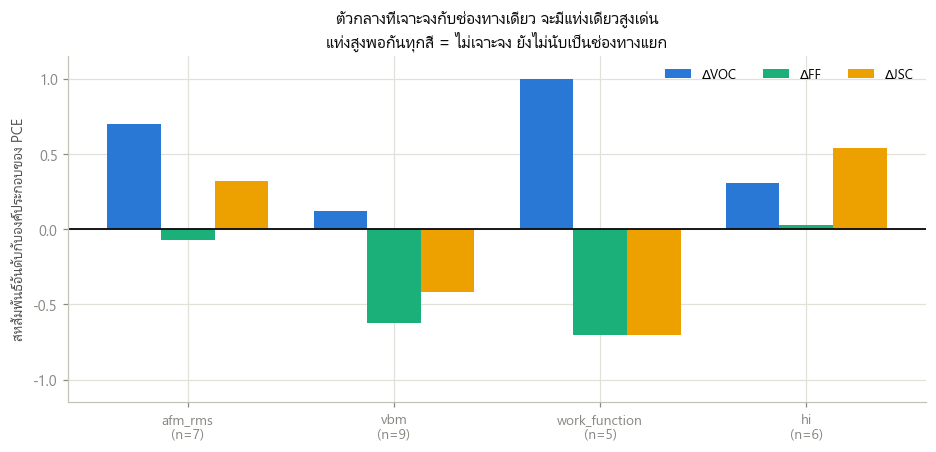

In [13]:
NEWMED = ["afm_rms", "vbm", "work_function", "hi"]
rows = []
for y in NEWMED:
    v = CHP[f"Δ{y}"].dropna() if f"Δ{y}" in CHP.columns else pd.Series(dtype=float)
    if len(v) < 2:
        continue
    p_, k_, n_ = sign_test(v)
    r = dict(ตัวกลาง=y, n_paper=n_, ค่ากลาง=round(float(v.median()), 4),
             ทิศบวก=f"{k_}/{n_}", p=round(p_, 4) if pd.notna(p_) else np.nan)
    for t_ in ["voc", "ff", "jsc"]:
        rr, nn = spearman(CHP[f"Δ{y}"], CHP[f"Δ{t_}"])
        r[f"เกาะ_Δ{t_}"] = round(rr, 2) if pd.notna(rr) else np.nan
    rows.append(r)
NEW = pd.DataFrame(rows)
display(NEW.set_index("ตัวกลาง"))

fig, ax = plt.subplots(figsize=(8.6, 4.2))
w, xs = 0.26, np.arange(len(NEW))
for i, (t_, c_) in enumerate([("voc", C1), ("ff", C3), ("jsc", C4)]):
    ax.bar(xs + (i - 1) * w, NEW[f"เกาะ_Δ{t_}"], w, color=c_, label=f"Δ{t_.upper()}")
ax.axhline(0, color=INK, lw=1.2)
ax.set_xticks(xs, [f"{r.ตัวกลาง}\n(n={int(r.n_paper)})" for r in NEW.itertuples()], fontsize=9)
ax.set_ylabel("สหสัมพันธ์อันดับกับองค์ประกอบของ PCE"); ax.set_ylim(-1.15, 1.15)
ax.legend(frameon=False, fontsize=8.6, ncol=3)
ax.set_title("ตัวกลางที่เจาะจงกับช่องทางเดียว จะมีแท่งเดียวสูงเด่น\nแท่งสูงพอกันทุกสี = ไม่เจาะจง ยังไม่นับเป็นช่องทางแยก")
plt.tight_layout(); plt.show()

**ผลไม่สนับสนุนสมมุติฐานช่องทางที่สาม** และมีจุดที่ต้องอ่านอย่างระวัง

`work_function` เกาะกับ ΔVoc แน่นมาก แต่ยืนบนเปเปอร์เพียง 5 ฉบับ — ที่ n เท่านี้ สหสัมพันธ์สูงสุด
เกิดขึ้นได้ไม่ยากด้วยความบังเอิญ · ส่วน `vbm` ซึ่งครอบคลุมมากกว่า (9 เปเปอร์) กลับ**ไม่มีสัญญาณทิศทาง**เลย
สองตัวนี้วัดเรื่องเดียวกันแต่ให้คำตอบขัดกัน จึงยังสรุปว่ามีช่องพลังงานไม่ได้

`afm_rms` ก็**ไม่ได้หนุนช่องสัณฐานอย่างที่ตั้งสมมุติฐานไว้** — ผิวเรียบขึ้นทุกเปเปอร์ที่วัด (7/7)
แต่ไปเกาะกับ ΔVoc มากกว่า ΔJsc สวนทางกับที่คาด

> **บันทึกไว้ว่านี่คือสมมุติฐานที่ทดสอบแล้วไม่ผ่าน** ไม่ใช่ผลที่ซ่อนไว้ ·
> ทางเดียวที่จะตัดสินได้คือเก็บเปเปอร์ที่วัด UPS/AFM เพิ่ม

## 7.4 เสถียรภาพ — คำถามที่ยังไม่เคยถาม

`retention_25c` และ `degradation_rate` อยู่ใน `target_table` มาตลอดแต่**ไม่เคยถูกวิเคราะห์**
ทั้งที่เสถียรภาพคือคอขวดจริงของเพอรอฟสไกต์ ไม่ใช่ประสิทธิภาพ

ใช้วิธีเดียวกับ §6 ทุกประการ — เทียบกับอุปกรณ์ควบคุมในเปเปอร์เดียวกัน แล้วรวมระดับเปเปอร์

| ตัวชี้วัด | ทิศทางที่ดี |
|---|---|
| `retention_25c` | **สูงขึ้น** = เหลือประสิทธิภาพมากกว่าหลังทดสอบ |
| `degradation_rate` | **ต่ำลง** = เสื่อมช้าลง |

สองตัวนี้วัดคนละมุมของเรื่องเดียวกัน ถ้าทั้งคู่ชี้ไปทางเดียวกัน หลักฐานแข็งขึ้นมาก

,n_paper,ค่ากลาง,CI95_ล่าง,CI95_บน,ทิศบวก,ดีขึ้นกี่เปเปอร์,p
ตัวชี้วัด,,,,,,,
retention_25c,7,10.000,7.0000,25.0000,7/7,7/7,0.0156
degradation_rate,7,-0.017,-0.1389,-0.0064,0/7,7/7,0.0156



สองตัวชี้วัดสอดคล้องกันเอง: สหสัมพันธ์ -0.89 (n=7 เปเปอร์)
เสถียรภาพดีขึ้น มาพร้อม PCE ดีขึ้นไหม: rho +0.25 (n=7)
  -> ถ้าใกล้ 0 แปลว่าเป็นผลคนละแกน ไม่ใช่ผลพลอยได้ของ PCE ที่สูงขึ้น


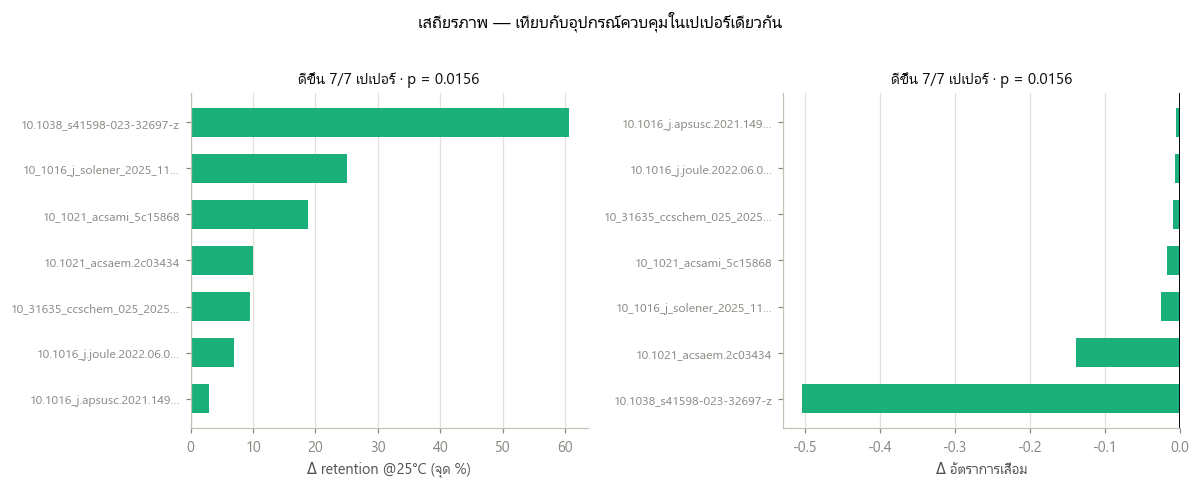

⚠️ n เพียง 7 เปเปอร์ และอคติจากการตีพิมพ์ใช้ได้เต็มที่กับผลนี้เช่นกัน


In [14]:
rows = []
for y, good in [("retention_25c", +1), ("degradation_rate", -1)]:
    v = CHP[f"Δ{y}"].dropna()
    if len(v) < 2:
        continue
    p_, k_, n_ = sign_test(v)
    lo, hi = boot_ci(v)
    rows.append(dict(ตัวชี้วัด=y, n_paper=n_, ค่ากลาง=round(float(v.median()), 4),
                     CI95_ล่าง=round(lo, 4), CI95_บน=round(hi, 4),
                     ทิศบวก=f"{k_}/{n_}",
                     ดีขึ้นกี่เปเปอร์=f"{(k_ if good > 0 else n_ - k_)}/{n_}",
                     p=round(p_, 4) if pd.notna(p_) else np.nan))
STAB_TBL = pd.DataFrame(rows)
display(STAB_TBL.set_index("ตัวชี้วัด"))

_ret = CHP["Δretention_25c"].dropna()
_deg = CHP["Δdegradation_rate"].dropna()
_both = CHP[["Δretention_25c", "Δdegradation_rate", "Δpce"]].dropna()
_r, _n = spearman(_both["Δretention_25c"], _both["Δdegradation_rate"])
print(f"\nสองตัวชี้วัดสอดคล้องกันเอง: สหสัมพันธ์ {_r:+.2f} (n={_n} เปเปอร์)")
_rp, _np = spearman(_both["Δretention_25c"], _both["Δpce"])
print(f"เสถียรภาพดีขึ้น มาพร้อม PCE ดีขึ้นไหม: rho {_rp:+.2f} (n={_np})")
print("  -> ถ้าใกล้ 0 แปลว่าเป็นผลคนละแกน ไม่ใช่ผลพลอยได้ของ PCE ที่สูงขึ้น")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.3))
for ax, (y, lab, good) in zip(axes, [("Δretention_25c", "Δ retention @25°C (จุด %)", +1),
                                     ("Δdegradation_rate", "Δ อัตราการเสื่อม", -1)]):
    v = CHP[y].dropna().sort_values()
    col = [C3 if (x * good) > 0 else C2 for x in v]
    ax.barh(range(len(v)), v.values, color=col, height=.62)
    ax.axvline(0, color=INK, lw=1.3)
    ax.set_yticks(range(len(v)), [short(i, 26) for i in v.index], fontsize=8)
    ax.set_xlabel(lab)
    _p, _k, _n2 = sign_test(v)
    ax.set_title(f"ดีขึ้น {(_k if good > 0 else _n2 - _k)}/{_n2} เปเปอร์ · p = {_p:.3g}", fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("เสถียรภาพ — เทียบกับอุปกรณ์ควบคุมในเปเปอร์เดียวกัน", y=1.02)
plt.tight_layout(); plt.show()
print("⚠️ n เพียง 7 เปเปอร์ และอคติจากการตีพิมพ์ใช้ได้เต็มที่กับผลนี้เช่นกัน")

## 8. ปริมาณสารที่ใช้ — ยิ่งมากยิ่งดีหรือมีจุดเหมาะสม

`htl_dose` มีค่าแค่ 49/95 อุปกรณ์ ถ้าใส่รวมในโมเดลหลักจะตัดอุปกรณ์ทิ้งครึ่งหนึ่ง จึงแยกมาทำที่นี่
และเนื่องจากหน่วยของปริมาณต่างกันข้ามเปเปอร์ (mg/mL · vol% · mol%) จึงเทียบเป็น**อันดับภายในเปเปอร์**
ไม่ใช่ค่าดิบ — คำถามคือรูปร่างของเส้น ไม่ใช่ตัวเลขสัมบูรณ์

,จุดที่ไล่,ปริมาณที่ดีสุด,PCE_ที่ดีสุด,rho,รูปแบบ,ดีสุดที่จุดกลาง
เปเปอร์,,,,,,
10.1016_j.solmat.2025.113858,3,0.05,22.22,-1.00,ลงตลอด,False
10.1016j.nanoen.2021.106285,2,5.00,21.90,NaN,มีจุดเหมาะสม,False
10_1002_aenm_202405016,3,2.00,25.66,0.87,มีจุดเหมาะสม,False
10_1016_j_heliyon_2024_e25352,4,10.00,20.50,-0.40,มีจุดเหมาะสม,True
10_31635_ccschem_025_202505977,2,2.00,25.28,NaN,มีจุดเหมาะสม,False


เปเปอร์ที่จุดดีที่สุดอยู่ 'ตรงกลาง' ไม่ใช่ปลายสุด: 1/5
อ่านว่า: ถ้าดีสุดอยู่ตรงกลาง แปลว่าเติมมากขึ้นเรื่อย ๆ ไม่ได้ดีขึ้นเรื่อย ๆ — มีจุดเหมาะสมจริง


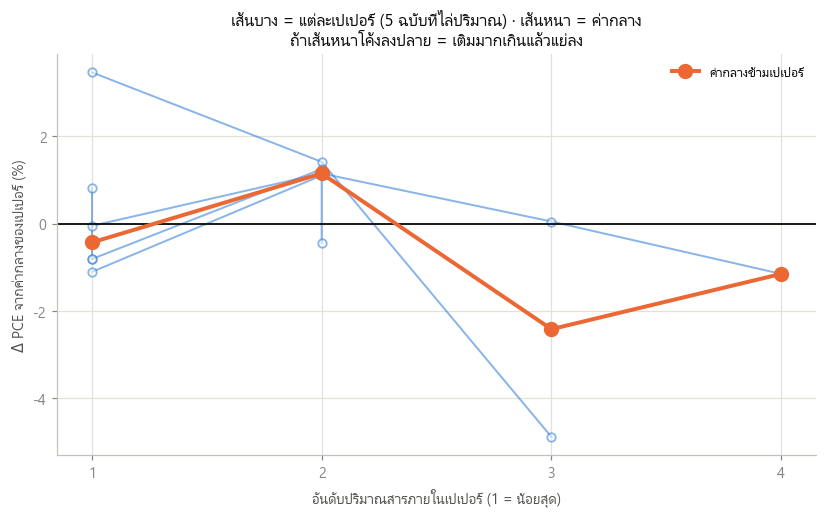

In [15]:
dose_papers = [p for p, g in F.groupby("paper") if g["htl_dose"].nunique(dropna=True) > 1]
D = F[F.paper.isin(dose_papers)].dropna(subset=["htl_dose", "pce"]).copy()
D["อันดับปริมาณ"] = D.groupby("paper")["htl_dose"].rank(method="dense")
D["Δpce"] = D["pce"] - D.groupby("paper")["pce"].transform("mean")

rows = []
for p, g in D.groupby("paper"):
    g = g.sort_values("htl_dose")
    r, n = spearman(g.htl_dose, g.pce)
    best = g.loc[g.pce.idxmax()]
    rows.append(dict(เปเปอร์=short(p, 32), จุดที่ไล่=len(g), ปริมาณที่ดีสุด=best.htl_dose,
                     PCE_ที่ดีสุด=round(float(best.pce), 2), rho=round(r, 2) if pd.notna(r) else np.nan,
                     รูปแบบ=("ขึ้นตลอด" if pd.notna(r) and r > 0.9 else
                             "ลงตลอด" if pd.notna(r) and r < -0.9 else "มีจุดเหมาะสม"),
                     ดีสุดที่จุดกลาง=bool(best.htl_dose not in (g.htl_dose.min(), g.htl_dose.max()))))
DOSE = pd.DataFrame(rows)
display(DOSE.set_index("เปเปอร์"))
print(f"เปเปอร์ที่จุดดีที่สุดอยู่ 'ตรงกลาง' ไม่ใช่ปลายสุด: {int(DOSE.ดีสุดที่จุดกลาง.sum())}/{len(DOSE)}")
print("อ่านว่า: ถ้าดีสุดอยู่ตรงกลาง แปลว่าเติมมากขึ้นเรื่อย ๆ ไม่ได้ดีขึ้นเรื่อย ๆ — มีจุดเหมาะสมจริง")

fig, ax = plt.subplots(figsize=(7.6, 4.8))
for p, g in D.groupby("paper"):
    g = g.sort_values("อันดับปริมาณ")
    ax.plot(g["อันดับปริมาณ"], g["Δpce"], "-o", ms=5.5, lw=1.3, color=C1, alpha=0.55,
            markerfacecolor="white", mew=1.2)
agg = D.groupby("อันดับปริมาณ")["Δpce"].median()
ax.plot(agg.index, agg.values, "-o", ms=9, lw=2.6, color=C2, label="ค่ากลางข้ามเปเปอร์", zorder=5)
ax.axhline(0, color=INK, lw=1.2)
ax.set_xlabel("อันดับปริมาณสารภายในเปเปอร์ (1 = น้อยสุด)")
ax.set_ylabel("Δ PCE จากค่ากลางของเปเปอร์ (%)")
ax.set_xticks(sorted(D["อันดับปริมาณ"].unique()))
ax.legend(frameon=False, fontsize=8.6)
ax.set_title(f"เส้นบาง = แต่ละเปเปอร์ ({len(dose_papers)} ฉบับที่ไล่ปริมาณ) · เส้นหนา = ค่ากลาง\nถ้าเส้นหนาโค้งลงปลาย = เติมมากเกินแล้วแย่ลง")
plt.tight_layout(); plt.show()

## 9. ผลนี้เสถียรแค่ไหนถ้าเปลี่ยนชุดเปเปอร์

ที่ N เท่านี้ อันดับความสำคัญของตัวแปรไม่เสถียร — เอกสารข้อจำกัดระบุไว้ตั้งแต่ต้น
จึงต้องวัดตรง ๆ ว่า **ถ้าสุ่มเปเปอร์ใหม่ ตัวแปรเดิมยังขึ้นเป็นอันดับหนึ่งอยู่กี่ % ของครั้ง**

สุ่มเปเปอร์ซ้ำ (ไม่ใช่สุ่มอุปกรณ์ — อุปกรณ์ในเปเปอร์เดียวกันไม่เป็นอิสระต่อกัน) แล้วฝึกใหม่ทั้งชุด
ตัวเลขที่ได้คือความน่าเชื่อถือของ *ลำดับ* ไม่ใช่ของขนาดผล

,อันดับ_ค่ากลาง,ขึ้นอันดับ_1,ติด_3_อันดับแรก,บทบาท
htl_mod_kind,1.0,100%,100%,ตัวแปรหลัก
htl_route,2.0,0%,68%,ตัวแปรหลัก
htl_dope,4.0,0%,40%,ตัวแปรหลัก
x_Br,4.0,0%,38%,ตัวควบคุม
a_FA,5.0,0%,23%,ตัวควบคุม
etl_family,5.0,0%,32%,ตัวควบคุม
a_Cs,7.0,0%,0%,ตัวควบคุม


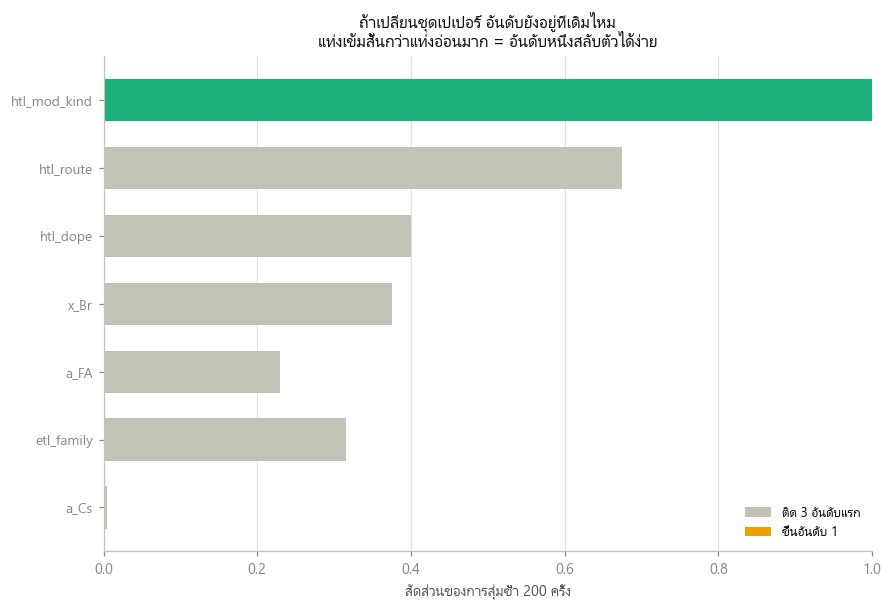

In [16]:
papers = F["paper"].unique()
rng = np.random.default_rng(SEED)
ranks = []
for _ in range(200):
    pick = rng.choice(papers, size=len(papers), replace=True)
    idx = np.concatenate([np.flatnonzero((G == p) & F["pce"].notna().values) for p in pick])
    if len(idx) < 20:
        continue
    Xb, gb = X.iloc[idx], G[idx]
    yb = paper_center(F["pce"].values[idx], gb, np.arange(len(idx))).values
    m = RandomForestRegressor(n_estimators=250, min_samples_leaf=2, max_features=0.6,
                              random_state=SEED, n_jobs=1).fit(Xb, yb)
    sv = pd.Series(np.abs(shap.TreeExplainer(m).shap_values(Xb)).mean(axis=0), index=Xb.columns)
    ranks.append(sv.groupby(sv.index.map(OWNER)).sum().rank(ascending=False))

RK = pd.DataFrame(ranks)
STAB = pd.DataFrame({
    "อันดับ_ค่ากลาง": RK.median(),
    "ขึ้นอันดับ_1": (RK == 1).mean(),
    "ติด_3_อันดับแรก": (RK <= 3).mean(),
    "บทบาท": ["ตัวแปรหลัก" if c in MAIN else "ตัวควบคุม" for c in RK.columns],
}).sort_values("อันดับ_ค่ากลาง")
display(STAB.assign(**{c: STAB[c].map("{:.0%}".format) for c in ["ขึ้นอันดับ_1", "ติด_3_อันดับแรก"]}))

fig, ax = plt.subplots(figsize=(8.2, 0.52 * len(STAB) + 2.0))
o = STAB.iloc[::-1]
ax.barh(range(len(o)), o["ติด_3_อันดับแรก"], color=BASE, height=0.62, label="ติด 3 อันดับแรก")
ax.barh(range(len(o)), o["ขึ้นอันดับ_1"],
        color=[C3 if b == "ตัวแปรหลัก" else C4 for b in o.บทบาท], height=0.62, label="ขึ้นอันดับ 1")
ax.set_yticks(range(len(o)), o.index, fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel(f"สัดส่วนของการสุ่มซ้ำ {len(ranks)} ครั้ง")
ax.legend(frameon=False, fontsize=8.6, loc="lower right")
ax.set_title("ถ้าเปลี่ยนชุดเปเปอร์ อันดับยังอยู่ที่เดิมไหม\nแท่งเข้มสั้นกว่าแท่งอ่อนมาก = อันดับหนึ่งสลับตัวได้ง่าย")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 10. ที่มาของทุกตัวเลข — เปเปอร์ไหนบ้างที่หนุนข้ออ้างแต่ละข้อ

ทุกข้ออ้างในโน้ตบุ๊กนี้เขียนเป็น "n เปเปอร์" แต่ตัวเลข n อย่างเดียวตรวจสอบย้อนไม่ได้
ส่วนนี้จึงเขียน **รายชื่อ DOI ที่หนุนข้ออ้างแต่ละข้อ** ออกมาให้ครบ เพื่อเปิดเปเปอร์ตรวจด้วยมือได้

ออกเป็นสองไฟล์ที่ใช้คนละแบบ

| ไฟล์ | หนึ่งแถวคือ | ใช้ตอนไหน |
|---|---|---|
| `paper_provenance.csv` | หนึ่ง**ข้ออ้าง** + รายชื่อเปเปอร์ที่หนุน | "ตัวเลข +1.99% นี้มาจากเปเปอร์ไหนบ้าง" |
| `paper_evidence_table.csv` | หนึ่ง**เปเปอร์** + ทุกค่าที่มันให้ | "เปิดเปเปอร์นี้แล้วต้องเจอเลขอะไรบ้าง" |

`paper_evidence_table.csv` มีคอลัมน์ `ค่าฐาน` (ของอุปกรณ์ควบคุม) และ `ค่าหลังดัดแปลง` คู่กับ Δ
เพื่อให้เทียบกับตัวเลขในเปเปอร์ได้ตรง ๆ โดยไม่ต้องคำนวณย้อนเอง

In [17]:
PROV = []


def claim(หัวข้อ, ข้ออ้าง, papers, หมายเหตุ=""):
    ps = sorted(set(papers))
    PROV.append({"หัวข้อ": หัวข้อ, "ข้ออ้าง": ข้ออ้าง, "n_เปเปอร์": len(ps),
                 "รายชื่อเปเปอร์": " ; ".join(ps), "หมายเหตุ": หมายเหตุ})


_all_pap = sorted(F.paper.unique())
_ctrl_pap = sorted(MED.paper.unique())
claim("§0 ชุดข้อมูล", f"อุปกรณ์ {len(F)} ตัว จากเปเปอร์ {len(_all_pap)} ฉบับ", _all_pap)
claim("§0 ชุดข้อมูล", "เปเปอร์ที่มีทั้งอุปกรณ์ควบคุมและอุปกรณ์ที่ดัดแปลง (ใช้วัด Δ ได้)", _ctrl_pap)
claim("§0 ชุดข้อมูล", "เปเปอร์ที่ไม่มีอุปกรณ์ควบคุม -- วัด Δ ไม่ได้",
      set(_all_pap) - set(_ctrl_pap), "ดัดแปลงทุกตัว หรือไม่ดัดแปลงเลยทั้งฉบับ")

# วนทุกคอลัมน์ Δ ที่มีจริง -- ระบุชื่อไว้ตายตัวทำให้ตัวกลางที่เพิ่มใหม่หายจาก provenance เงียบ ๆ
for y in [c for c in CHP.columns if c.startswith("Δ")]:
    g = CHP[y].dropna()
    if len(g) >= 2:
        p_, k_, n_ = sign_test(g)
        claim("§6-7 ขนาดผล", f"{y} ค่ากลาง {g.median():+.4g} · ทิศบวก {k_}/{n_} · p={p_:.4g}",
              g.index)

for lv, g in CLS.groupby("ระดับ"):
    v = g.dropna(subset=["Δpce"])
    claim("§6 จัดอันดับกลุ่มสาร", f"{lv}: ΔPCE ค่ากลาง {v['Δpce'].median():+.3f}", v.paper)
_no = sorted(set(F.loc[F.htl_mod_class != "ไม่ดัดแปลง", "htl_mod_class"]) - set(CLS["ระดับ"]))
for lv in _no:
    _p = sorted(F.loc[F.htl_mod_class == lv, "paper"].unique())
    claim("§6 จัดอันดับกลุ่มสาร", f"{lv}: ไม่มีแถว -- ไม่มีคู่เทียบ", _p,
          "เปเปอร์ที่ใช้สารกลุ่มนี้ไม่มีอุปกรณ์ควบคุมของตัวเอง")

for lv, g in CHP2.groupby("ช่องทาง"):
    claim("§7.2 ช่องทาง", f"{lv}", g.index, f"เกณฑ์ ΔสัมพัทธЬ > {THR:.0%}".replace("Ь", "ธ"))

claim("§8 ปริมาณสาร", f"เปเปอร์ที่ไล่ปริมาณมากกว่าหนึ่งระดับ", dose_papers)
claim("§9 ความเสถียร", f"สุ่มเปเปอร์ซ้ำ {len(ranks)} ครั้งจากชุดนี้", _all_pap)
for m in ["vtfl", "trap_density", "contact_angle", "grain_size", "retention_25c"]:
    _p = sorted(F.loc[F[m].notna(), "paper"].unique()) if m in F.columns else []
    claim("§7 ความครอบคลุมตัวกลาง", f"เปเปอร์ที่วัด {m}", _p)

PROV = pd.DataFrame(PROV)
display(PROV[["หัวข้อ", "ข้ออ้าง", "n_เปเปอร์"]])

# ---- ตารางรายเปเปอร์: เปิดเปเปอร์แล้วเช็คได้ทีละแถว ----
ev = []
for p, g in F.groupby("paper"):
    ctrl, trt = g[g.htl_mod_kind == "ไม่ดัดแปลง"], g[g.htl_mod_kind != "ไม่ดัดแปลง"]
    r = {"เปเปอร์": p, "อุปกรณ์": len(g), "ควบคุม": len(ctrl), "ดัดแปลง": len(trt),
         "สารที่ใช้": " ; ".join(sorted(trt.htl_mod_material.dropna().unique())) or "-",
         "กลุ่มสาร": " ; ".join(sorted(trt.htl_mod_class.dropna().unique())) or "-"}
    for y in ["pce", "ff", "voc", "jsc", "vtfl", "contact_angle", "grain_size",
              "afm_rms", "vbm", "work_function", "hi", "retention_25c", "degradation_rate"]:
        b = ctrl[y].mean() if len(ctrl) else np.nan
        o = trt[y].mean() if len(trt) else np.nan
        r[f"{y}_ควบคุม"] = round(b, 4) if pd.notna(b) else np.nan
        r[f"{y}_ดัดแปลง"] = round(o, 4) if pd.notna(o) else np.nan
        r[f"{y}_Δ"] = round(o - b, 4) if pd.notna(b) and pd.notna(o) else np.nan
    r["ช่องทาง"] = CHP2["ช่องทาง"].get(p, "-")
    ev.append(r)
EV = pd.DataFrame(ev).sort_values("เปเปอร์")
display(EV[["เปเปอร์", "อุปกรณ์", "ควบคุม", "ดัดแปลง", "กลุ่มสาร",
            "pce_ควบคุม", "pce_ดัดแปลง", "pce_Δ", "ช่องทาง"]])
print(f"\nตารางรายเปเปอร์ {len(EV)} แถว · เปเปอร์ที่วัด Δ ได้ {int(EV['pce_Δ'].notna().sum())} ฉบับ")

,หัวข้อ,ข้ออ้าง,n_เปเปอร์
0,§0 ชุดข้อมูล,อุปกรณ์ 95 ตัว จากเปเปอร์ 31 ฉบับ,31
1,§0 ชุดข้อมูล,เปเปอร์ที่มีทั้งอุปกรณ์ควบคุมและอุปกรณ์ที่ดัดแ...,22
2,§0 ชุดข้อมูล,เปเปอร์ที่ไม่มีอุปกรณ์ควบคุม -- วัด Δ ไม่ได้,9
3,§6-7 ขนาดผล,Δpce ค่ากลาง +1.995 · ทิศบวก 21/22 · p=1.097e-05,22
4,§6-7 ขนาดผล,Δff ค่ากลาง +1.962 · ทิศบวก 20/22 · p=0.0001211,22
5,§6-7 ขนาดผล,Δvoc ค่ากลาง +0.0475 · ทิศบวก 18/22 · p=0.004344,22
6,§6-7 ขนาดผล,Δjsc ค่ากลาง +0.6217 · ทิศบวก 20/22 · p=0.0001211,22
7,§6-7 ขนาดผล,Δvtfl ค่ากลาง -0.145 · ทิศบวก 0/13 · p=0.0002441,13
8,§6-7 ขนาดผล,Δtrap_density ค่ากลาง -1.645e+15 · ทิศบวก 0/12...,12
9,§6-7 ขนาดผล,Δcontact_angle ค่ากลาง +14.3 · ทิศบวก 8/11 · p...,11


,เปเปอร์,อุปกรณ์,ควบคุม,ดัดแปลง,กลุ่มสาร,pce_ควบคุม,pce_ดัดแปลง,pce_Δ,ช่องทาง
0,10.1002admi.202500231,4,1,3,เกลือไอออน,16.3100,16.7767,0.4667,ทั้งสองช่อง
1,10.1007_s10854-017-8094-9,4,4,0,-,10.9750,NaN,NaN,-
2,10.1016.jpowsour.2020.228738,2,1,1,โมเลกุลอินทรีย์,18.8400,20.7400,1.9000,ทั้งสองช่อง
3,10.1016_j.apsusc.2021.149973,2,1,1,โมเลกุลอินทรีย์,18.7100,20.2100,1.5000,ช่อง Jsc อย่างเดียว
4,10.1016_j.joule.2022.06.026,4,1,3,โมเลกุลอินทรีย์,19.6000,21.9667,2.3667,ช่อง Jsc อย่างเดียว
5,10.1016_j.solener.2024.112888,2,2,0,-,10.6500,NaN,NaN,-
6,10.1016_j.solmat.2025.113858,4,1,3,โมเลกุลอินทรีย์,20.1900,18.7533,-1.4367,ไม่ขยับทั้งคู่
7,10.1016j.jechem.2021.11.029,2,1,1,โมเลกุลอินทรีย์,17.8300,20.1600,2.3300,ทั้งสองช่อง
8,10.1016j.nanoen.2021.106285,3,0,3,ออกไซด์,NaN,21.0900,NaN,-
9,10.1021_acsaem.2c03434,2,1,1,โมเลกุลอินทรีย์,16.2000,17.9800,1.7800,ช่อง FF อย่างเดียว



ตารางรายเปเปอร์ 31 แถว · เปเปอร์ที่วัด Δ ได้ 22 ฉบับ


## 11. สรุป · ข้อเสนอต่อแล็บ · ข้อจำกัดที่ต้องประกาศทุกครั้ง

In [18]:
OOF = res_ctr[(BEST_MODEL, BEST_SET)].copy()
OOF["แบบจำลอง"] = f"{BEST_MODEL} · {BEST_SET}"
for name, df in [("model_scores_by_block.csv", ABS1), ("model_block_mirror.csv", CMP.reset_index(names="บล็อก")),
                 ("model_scores_absolute.csv", ABS2), ("model_scores_centered.csv", CTR1),
                 ("model_importance.csv", IMP.reset_index().rename(columns={"index": "ตัวแปร"})),
                 ("model_class_ranking.csv", RANK), ("model_mediation.csv", MEDTBL),
                 ("model_dose_response.csv", DOSE), ("model_stability.csv", STAB.reset_index().rename(columns={"index": "ตัวแปร"})),
                 ("model_oof_predictions.csv", OOF), ("model_paper_contrasts.csv", MED),
                 ("model_channel_correlations.csv", COR),
                 ("model_new_mediators.csv", NEW), ("model_stability_effect.csv", STAB_TBL),
                 ("paper_provenance.csv", PROV), ("paper_evidence_table.csv", EV)]:
    df.to_csv(OUT / name, index=False, encoding="utf-8-sig")
    print("เขียน processed/model/" + name)

r2_abs = score(res_abs[("ป่าสุ่ม", "ทั้งสองชุด")])["R2"]
r2_abs_main = score(res_abs[("ป่าสุ่ม", "ตัวแปรหลักอย่างเดียว")])["R2"]
r2_abs_ctrl = score(res_abs[("ป่าสุ่ม", "ตัวควบคุมอย่างเดียว")])["R2"]
r2_ctr_ctrl = score(res_ctr[("ป่าสุ่ม", "ตัวควบคุมอย่างเดียว")])["R2"]
r2_ctr = score(OOF)["R2"]
ceil_ = float(BASE_TBL.loc[BASE_TBL.ผลลัพธ์ == "pce", "เพดาน_R2"].iloc[0])
top_main = STAB[STAB.บทบาท == "ตัวแปรหลัก"].index[0]
allc = CLS.groupby("paper")["Δpce"].mean().dropna()   # หนึ่งค่าต่อเปเปอร์ ไม่นับซ้ำ
lo_a, hi_a = boot_ci(allc)
p_a, k_a, n_a = sign_test(allc)
mid = int(DOSE["ดีสุดที่จุดกลาง"].sum())

print(f"""
{'='*74}
1) ทำนายค่าสัมบูรณ์ของเปเปอร์ใหม่: R2 รวม = {r2_abs:+.3f}  (ตัวตนของเปเปอร์กินความแปรปรวนไป {ceil_:.0%})
   แต่แยกบล็อกแล้ว: ตัวควบคุมอย่างเดียว {r2_abs_ctrl:+.3f} · ตัวแปรหลักอย่างเดียว {r2_abs_main:+.3f}
   -> คะแนนบวกที่เห็นมาจากการจำสูตรเคมีของแต่ละแล็บ ไม่ใช่จากผลของการดัดแปลง
      นี่คือเหตุผลที่ห้ามรายงาน R2 ตัวเดียวโดยไม่แยกบล็อก

2) ทำนายส่วนต่างภายในเปเปอร์:      R2 = {r2_ctr:+.3f}   (ตัวควบคุมอย่างเดียวเหลือ {r2_ctr_ctrl:+.3f})
   -> ภาพสะท้อนสมบูรณ์: หลังลบค่ากลาง ตัวควบคุมกลายเป็นศูนย์ตามทฤษฎี และสิ่งที่เหลือคือตัวแปร HTL ล้วน
      คำถามที่ตอบได้คือ "ถ้าแล็บนี้ดัดแปลง จะดีขึ้นกว่าตัวเองเท่าไร" ซึ่งตรงกับที่แล็บอยากรู้จริง

3) ขนาดผลรวมของการดัดแปลงผิว HTL: ΔPCE ค่ากลาง {allc.median():+.2f} %
   ช่วงความเชื่อมั่น 95% [{lo_a:+.2f}, {hi_a:+.2f}] · ทิศบวก {k_a}/{n_a} เปเปอร์ · sign test p = {p_a:.4g}
   (ยุบเป็นหนึ่งค่าต่อเปเปอร์ก่อนแล้ว จึงไม่นับเปเปอร์ที่ทดสอบหลายกลุ่มสารซ้ำ)

3b) ปริมาณสาร: จุดที่ดีที่สุดอยู่ตรงกลางเพียง {mid}/{len(DOSE)} เปเปอร์ที่ไล่ปริมาณ
   -> สรุปได้แค่ว่า "ไม่ใช่ยิ่งมากยิ่งดี" ยังสรุปไม่ได้ว่า "มีจุดเหมาะสมตรงกลางเสมอ" (n เล็กเกินไป)

4) กลไก: ผลราว {prop:.0%} วิ่งผ่านการลดกับดักพาหะ (VTFL) ที่เหลือไปทางอื่น
   วัดจาก {len(both)} เปเปอร์ที่วัด VTFL -- ประมาณขนาดได้ ยังไม่ถึงขั้นพิสูจน์

5) ตัวแปรที่ขึ้นอันดับหนึ่งบ่อยที่สุด: {top_main}
   ({STAB.loc[top_main,'ขึ้นอันดับ_1']:.0%} ของการสุ่มเปเปอร์ซ้ำ -- อันดับสลับตัวได้ ให้ถืออย่างหลวม ๆ)
{'='*74}""")

เขียน processed/model/model_scores_by_block.csv
เขียน processed/model/model_block_mirror.csv
เขียน processed/model/model_scores_absolute.csv
เขียน processed/model/model_scores_centered.csv
เขียน processed/model/model_importance.csv
เขียน processed/model/model_class_ranking.csv
เขียน processed/model/model_mediation.csv
เขียน processed/model/model_dose_response.csv
เขียน processed/model/model_stability.csv
เขียน processed/model/model_oof_predictions.csv
เขียน processed/model/model_paper_contrasts.csv
เขียน processed/model/model_channel_correlations.csv
เขียน processed/model/model_new_mediators.csv
เขียน processed/model/model_stability_effect.csv
เขียน processed/model/paper_provenance.csv
เขียน processed/model/paper_evidence_table.csv

1) ทำนายค่าสัมบูรณ์ของเปเปอร์ใหม่: R2 รวม = +0.256  (ตัวตนของเปเปอร์กินความแปรปรวนไป 83%)
   แต่แยกบล็อกแล้ว: ตัวควบคุมอย่างเดียว +0.259 · ตัวแปรหลักอย่างเดียว -0.057
   -> คะแนนบวกที่เห็นมาจากการจำสูตรเคมีของแต่ละแล็บ ไม่ใช่จากผลของการดัดแปลง
      นี่คือเ

### สิ่งที่ส่งต่อให้แล็บ

| ลำดับ | สิ่งที่ควรลอง | มาจากผลข้อไหน |
|---|---|---|
| 1 | ทำคู่ควบคุม–ทดลองในรันเดียวกันเสมอ ห้ามเทียบข้ามรัน | §3 · §4 — ค่าสัมบูรณ์เทียบข้ามแล็บไม่ได้ แม้แต่โมเดลก็ทำไม่ได้ |
| 2 | ดัดแปลงผิว HTL แบบเคลือบทับ เป็นตัวแปรหลักที่ควรลองก่อน | §5 · §6 — ขนาดผลใหญ่ที่สุดและมีคู่เทียบมากที่สุด |
| 3 | ไล่ปริมาณสารอย่างน้อย 3 ระดับ อย่าลองค่าเดียว | §8 — มีเปเปอร์ที่ปริมาณน้อยสุดให้ผลดีที่สุด (เติมมากยิ่งแย่ลง) การลองค่าเดียวจึงพลาดจุดที่ดีได้ง่าย · ยังสรุปรูปร่างเส้นร่วมไม่ได้เพราะมีแค่ 5 เปเปอร์ |
| 4 | วัด SCLC / VTFL ควบคู่กับ J–V ทุกครั้ง | §7 — เป็นตัวแปรเดียวที่ยืนยันว่ากลไกเป็นไปตามที่คิด และคือส่วนที่ข้อมูลขาดที่สุด |
| 5 | ตรึงสูตรเคมีและชนิด ETL ให้เหมือนกันทั้งชุดการทดลอง | §1.2 — เป็น confounder ตัวใหญ่ที่สุด ถ้าเปลี่ยนไปด้วยจะแยกผลไม่ออก |

### ข้อจำกัดที่ต้องประกาศทุกครั้งที่รายงานตัวเลขจากโน้ตบุ๊กนี้

1. **อคติจากการตีพิมพ์** — เปเปอร์ตีพิมพ์เฉพาะการดัดแปลงที่สำเร็จ ขนาดผลที่วัดได้จึงหมายถึง
   *"การดัดแปลงที่ผ่านการคัดเลือกของแต่ละแล็บมาแล้ว ให้ผลเท่านี้"* ไม่ใช่ *"ดัดแปลงอะไรก็ได้แล้วจะดีขึ้น"*
2. **ไม่ใช่ข้อสรุปเชิงสาเหตุ** — เป็นการสังเคราะห์การทดลองที่คนอื่นทำ ไม่ใช่การทดลองสุ่มที่เราออกแบบเอง
   ผลทุกข้อคือ **สมมติฐานสำหรับการทดลองยืนยันในแล็บ**
3. **ตัวควบคุมตีความเป็นกลไกไม่ได้** — `a_Cs` `a_FA` `x_Br` `etl_family` แปรค่าภายในเปเปอร์ 0–1 ฉบับ
   ค่า SHAP ของมันสะท้อนความต่างระหว่างแล็บ ไม่ใช่ผลของสูตรเคมีเอง
4. **การวิเคราะห์กลไกยืนบนเปเปอร์ไม่ถึงสิบฉบับ** — สัดส่วนที่รายงานใน §7 มีช่วงความเชื่อมั่นกว้าง
   ใช้เป็นการประมาณขนาด ไม่ใช่ค่าที่ตายตัว
5. **ไม่ได้จูนไฮเปอร์พารามิเตอร์** — ตัวเลขทุกตัวมาจากค่าตั้งต้นที่ประกาศไว้ใน §2 ตั้งแต่ก่อนเห็นผล